0. Data Loading & Quality Checks

1. EDA & Temporal Splitting

2. Baseline Models & RTE Benchmark
   - Naive Forecast (48h)
   - Seasonal Naive (168h)
   - RTE D+1 Benchmark
   - MAE / RMSE Comparison

3. Statistical Models
   - Box-Jenkins
   - ARIMA / SARIMA
   - SARIMAX
   - Holt-Winters

4. Machine Learning
   - Feature Engineering
   - LightGBM
   - Walk-forward Validation

5. Deep Learning (optional)

6. Final Evaluation
   - Comparison with RTE and Baselines
   - MAE / RMSE
   - Forecast Uncertainty
   - Peak-hour Analysis
   - Business Recommendations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

---
# **0. Data Loading & Quality Checks**


In [ ]:
df = pd.read_csv("france_electricity_hourly.csv")

print("Shape:", df.shape)
display(df.head())
display(df.info())

Shape: (65710, 4)


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+0000,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+0000,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+0000,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+0000,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+0000,52972.0,52188.0,5.72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65710 entries, 0 to 65709
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime_utc        65710 non-null  object 
 1   load_mw             65703 non-null  float64
 2   rte_forecast_d1_mw  65703 non-null  float64
 3   temperature_c       65710 non-null  float64
dtypes: float64(3), object(1)
memory usage: 2.0+ MB


None

---
### **0.1 — Temporal Integrity & Missing Values**

We convert timestamps to UTC and check temporal consistency.

Results:

65,710 hourly observations (2019–June 2026).

No duplicated or missing timestamps.

7 missing values in both load_mw and rte_forecast_d1_mw, occurring during October daylight saving transitions.

Time zone strategy:

UTC: regular hourly spacing for time-series models and lags.

Europe/Paris: calendar features, forecasting deadline (before 12:00), and target hours (D+1).

In [3]:
# Convert datetime and set temporal index
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True)

df = df.set_index("datetime_utc").sort_index()
# Temporal audit
print("Start:", df.index.min())
print("End:", df.index.max())
print("Duplicated timestamps:", df.index.duplicated().sum())

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h",
    tz="UTC"
)

print("Expected hours:", len(expected_index))
print("Actual rows:", len(df))
print("Missing timestamps:", len(expected_index.difference(df.index)))

# Missing values
print("\nMissing values per column:")
print(df.isna().sum())

# Rows containing missing values
display(df[df.isna().any(axis=1)])

Start: 2019-01-01 00:00:00+00:00
End: 2026-06-30 21:00:00+00:00
Duplicated timestamps: 0
Expected hours: 65710
Actual rows: 65710
Missing timestamps: 0

Missing values per column:
load_mw               7
rte_forecast_d1_mw    7
temperature_c         0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2019-10-27 00:00:00+00:00,NaN,NaN,15.13
2020-10-25 00:00:00+00:00,NaN,NaN,13.64
2021-10-31 00:00:00+00:00,NaN,NaN,11.86
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2023-10-29 00:00:00+00:00,NaN,NaN,14.41
2024-10-27 00:00:00+00:00,NaN,NaN,12.97
2025-10-26 00:00:00+00:00,NaN,NaN,8.86


In [4]:
idx = df.index.get_loc("2022-10-30 00:00:00+00:00	")

display(df.iloc[idx-2:idx+3])

,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2022-10-29 22:00:00+00:00,39868.0,37338.0,15.46
2022-10-29 23:00:00+00:00,36837.0,34175.0,14.85
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2022-10-30 01:00:00+00:00,36126.0,31100.0,14.72
2022-10-30 02:00:00+00:00,31669.0,30612.0,13.97


---
### **0.2 — Missing Value Treatment & Descriptive Statistics**

We apply time-based linear interpolation to the 7 missing observations to preserve a continuous hourly series.

Save original observations in df_raw.

Interpolate load_mw and rte_forecast_d1_mw.

Exclude originally missing observations from final evaluation.

Inspect descriptive statistics for potential anomalies.

No future information is allowed when generating day-ahead forecasts.

In [5]:
# Preserve original data
df_raw = df.copy()

# Interpolate missing values
cols = ["load_mw", "rte_forecast_d1_mw"]
df[cols] = df[cols].interpolate(method="time")

# French local time for calendar and forecasting logic
df["datetime_fr"] = df.index.tz_convert("Europe/Paris")

# Verify interpolation and inspect descriptive statistics
print(df[cols].isna().sum())
display(df[["load_mw", "rte_forecast_d1_mw", "temperature_c"]].describe())

load_mw               0
rte_forecast_d1_mw    0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
count,65710.000000,65710.000000,65710.000000
mean,51497.351514,50830.222143,13.071639
std,11018.880178,11048.384887,7.022981
min,29364.000000,27712.000000,-5.090000
25%,43320.000000,42588.000000,7.920000
50%,49767.000000,48962.000000,12.500000
75%,58746.000000,58062.000000,17.980000
max,90210.000000,89975.000000,38.520000


In [6]:
idx = df.index.get_loc("2019-10-27 00:00:00+00:00")

display(df.iloc[idx-1:idx+2])

,load_mw,rte_forecast_d1_mw,temperature_c,datetime_fr
datetime_utc,,,,
2019-10-26 23:00:00+00:00,42172.0,40425.0,15.13,2019-10-27 01:00:00+02:00
2019-10-27 00:00:00+00:00,40558.5,38562.5,15.13,2019-10-27 02:00:00+02:00
2019-10-27 01:00:00+00:00,38945.0,36700.0,14.26,2019-10-27 02:00:00+01:00


--- 
# **1. EDA & Temporal Splitting**


### **1.0 Temporal Splitting**

In [7]:
local = df["datetime_fr"]

train = df.loc[local < pd.Timestamp("2025-01-01", tz="Europe/Paris")].copy()

val = df.loc[
    (local >= pd.Timestamp("2025-01-01", tz="Europe/Paris")) &
    (local < pd.Timestamp("2026-01-01", tz="Europe/Paris"))
].copy()

test = df.loc[
    local >= pd.Timestamp("2026-01-01", tz="Europe/Paris")
].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (52607, 4)
Validation: (8760, 4)
Test: (4343, 4)


### **1.1 — Exploratory Data Analysis**

We explore the hourly electricity consumption to identify long-term trends, seasonal patterns, and potential anomalies before modeling.

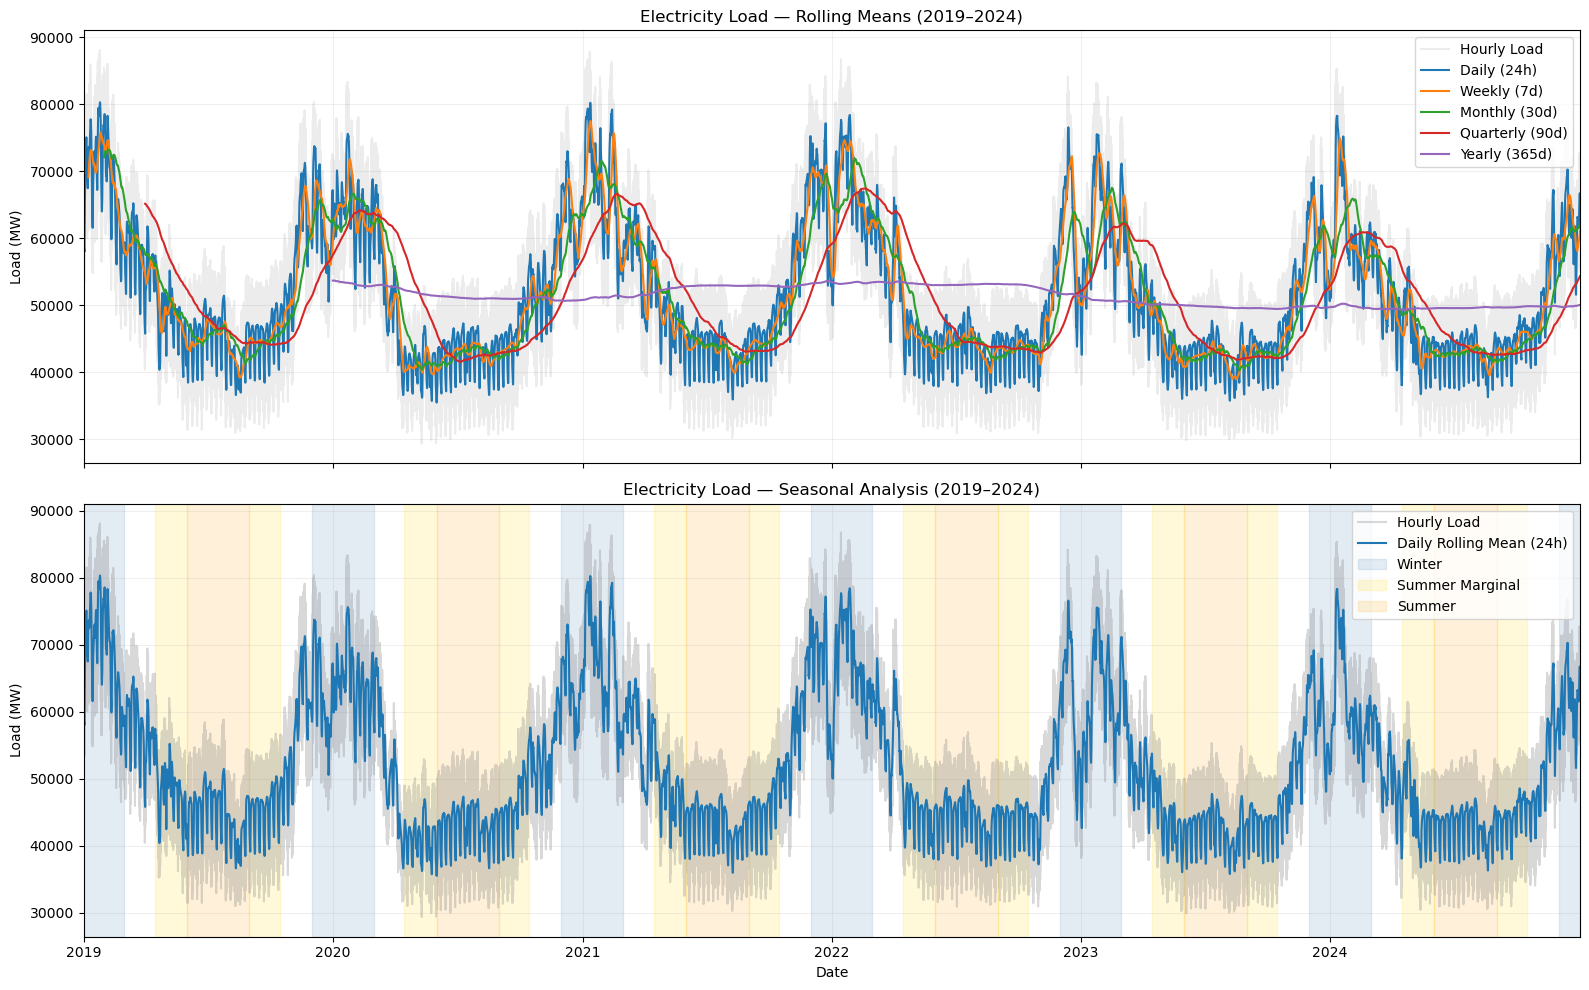

In [8]:
y = train["load_mw"]

windows = {
    "Daily (24h)": 24,
    "Weekly (7d)": 24 * 7,
    "Monthly (30d)": 24 * 30,
    "Quarterly (90d)": 24 * 90,
    "Yearly (365d)": 24 * 365
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# GRAPH 1 — Rolling means
ax = axes[0]

ax.plot(y.index, y, alpha=0.15, color="gray", label="Hourly Load")

for label, window in windows.items():
    ax.plot(
        y.index,
        y.rolling(window).mean(),
        label=label,
        linewidth=1.5
    )

ax.set_title("Electricity Load — Rolling Means (2019–2024)")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)


# GRAPH 2 — Seasonal analysis
ax = axes[1]

ax.plot(y.index, y, alpha=0.3, color="gray", label="Hourly Load")

ax.plot(
    y.index,
    y.rolling(24).mean(),
    linewidth=1.5,
    label="Daily Rolling Mean (24h)"
)

start_year = train["datetime_fr"].dt.year.min()
end_year = train["datetime_fr"].dt.year.max()

added_labels = set()

for year in range(start_year, end_year + 2):

    seasons = [
        ("Winter", f"{year-1}-12-01", f"{year}-03-01", "steelblue"),
        ("Summer Marginal", f"{year}-04-15", f"{year}-06-01", "gold"),
        ("Summer", f"{year}-06-01", f"{year}-09-01", "orange"),
        ("Summer Marginal", f"{year}-09-01", f"{year}-10-15", "gold"),
    ]

    for season, start, end, color in seasons:

        # Convert French local dates to UTC
        start = pd.Timestamp(start, tz="Europe/Paris").tz_convert("UTC")
        end = pd.Timestamp(end, tz="Europe/Paris").tz_convert("UTC")

        # Avoid duplicate labels
        label = season if season not in added_labels else None

        ax.axvspan(
            start,
            end,
            color=color,
            alpha=0.15,
            label=label
        )

        added_labels.add(season)

ax.set_xlim(y.index.min(), y.index.max())
ax.set_title("Electricity Load — Seasonal Analysis (2019–2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Comments :** 


-Significant short-term variability: hourly fluctuations are progressively smoothed by larger rolling windows, revealing the underlying seasonal structure.

- Relatively stable long-term level: the yearly rolling mean shows no strong sustained trend, despite some interannual variations.

- Strong annual seasonality: electricity demand peaks during winter, likely driven by heating needs, while summer exhibits significantly lower consumption.
- Refined seasonal interpretation: France's temperate climate suggests that the traditional winter/summer classification may be too simplistic. During late spring and early autumn, temperatures are often mild enough to limit residential heating demand. These Summer Marginal periods appear to share relatively low consumption levels with summer.

This motivates investigating more refined seasonal indicators rather than relying exclusively on calendar seasons.

### **Weekly Analysis**

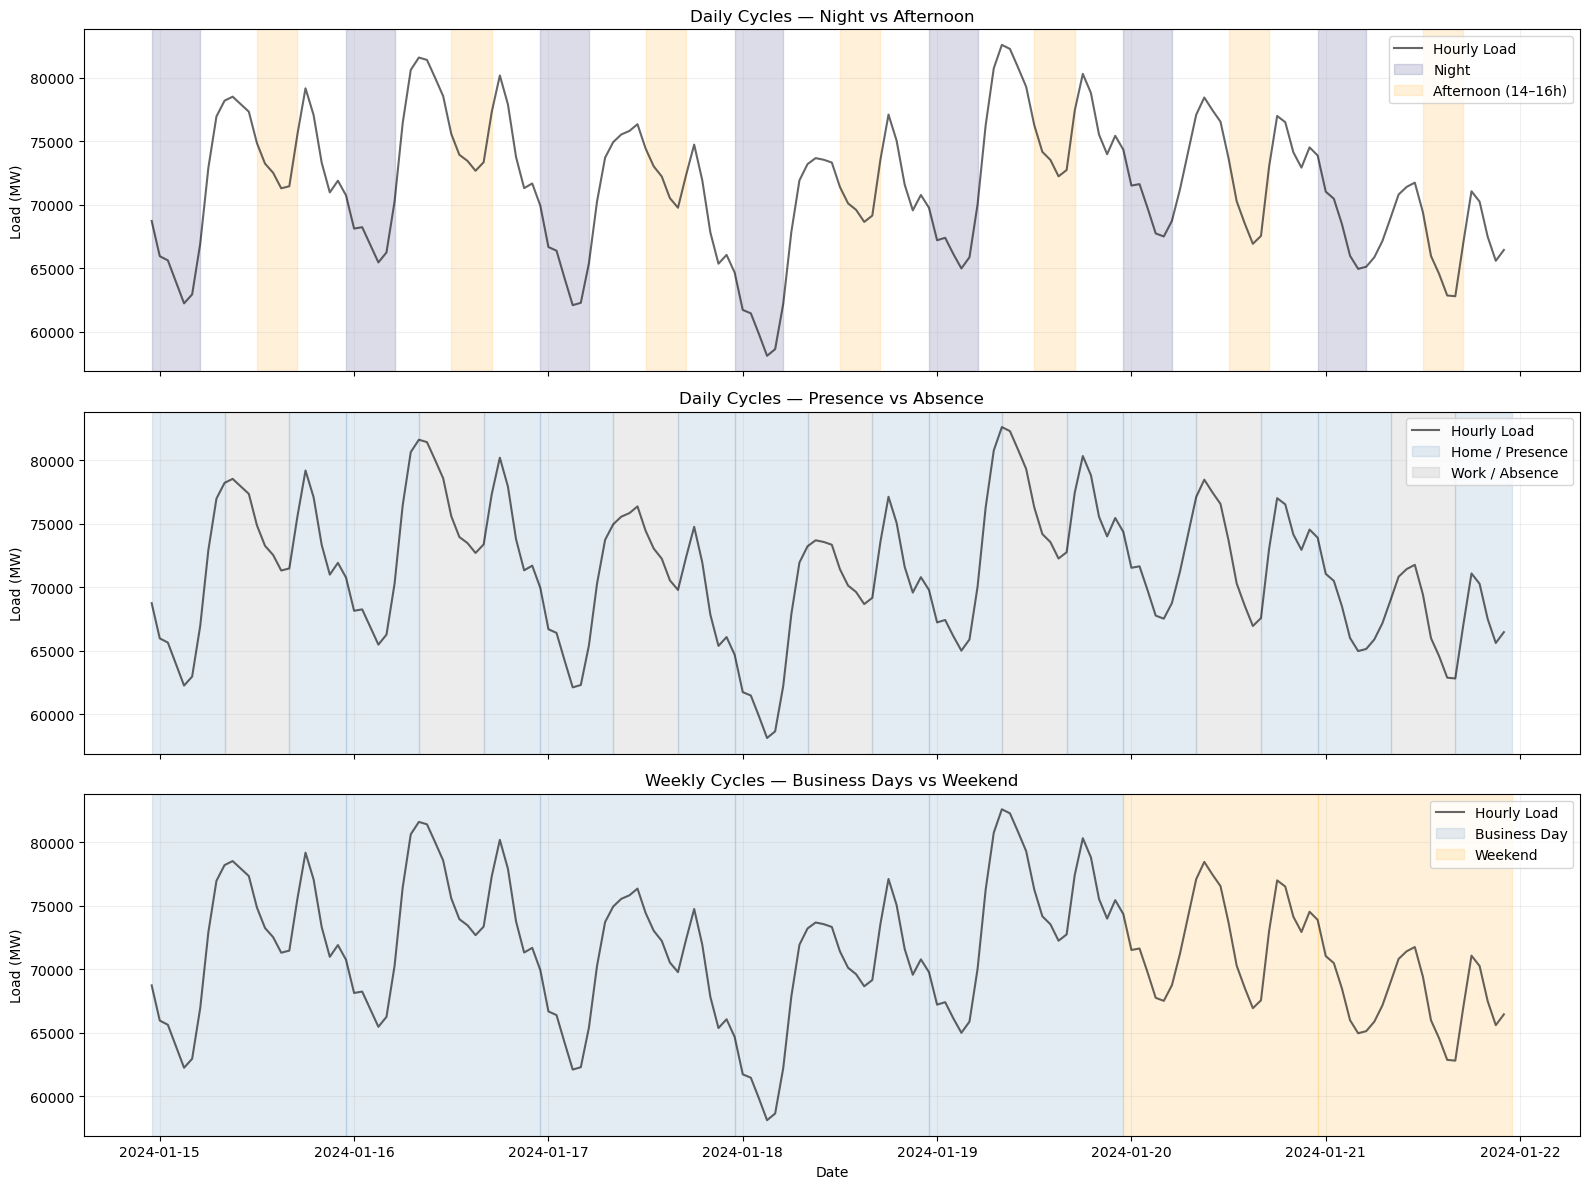

In [9]:
# One week from training data (French local dates)
local = train["datetime_fr"]
week = train.loc[
    (local >= pd.Timestamp("2024-01-15", tz="Europe/Paris")) &
    (local < pd.Timestamp("2024-01-22", tz="Europe/Paris")),
    "load_mw"
]

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax in axes:
    ax.plot(week.index, week, color="black", alpha=0.6, label="Hourly Load")
    ax.set_ylabel("Load (MW)")
    ax.grid(alpha=0.2)

# French local time periods
days = pd.date_range("2024-01-15", periods=7, freq="D", tz="Europe/Paris")

def shade(ax, day, start, end, color, label):
    ax.axvspan(
        (day + pd.Timedelta(hours=start)).tz_convert("UTC"),
        (day + pd.Timedelta(hours=end)).tz_convert("UTC"),
        color=color, alpha=0.15, label=label
    )

for i, day in enumerate(days):

    # Plot 1 — Night and afternoon
    shade(axes[0], day, 0, 6, "midnightblue", "Night" if i == 0 else None)
    shade(axes[0], day, 13, 18, "orange", "Afternoon (14–16h)" if i == 0 else None)

    # Plot 2 — Presence and absence
    shade(axes[1], day, 0, 9, "steelblue", "Home / Presence" if i == 0 else None)
    shade(axes[1], day, 9, 17, "gray", "Work / Absence" if i == 0 else None)
    shade(axes[1], day, 17, 24, "steelblue", None)

    # Plot 3 — Business days vs weekend
    if day.dayofweek < 5:
        shade(axes[2], day, 0, 24, "steelblue",
              "Business Day" if i == 0 else None)
    else:
        shade(axes[2], day, 0, 24, "orange",
              "Weekend" if i == 5 else None)

titles = [
    "Daily Cycles — Night vs Afternoon",
    "Daily Cycles — Presence vs Absence",
    "Weekly Cycles — Business Days vs Weekend"
]

for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### **Comments**

- **Intraday seasonality:** zooming into a representative week reveals recurring consumption fluctuations, with nighttime troughs and morning/evening peaks. This motivates us to explore peak and off-peak hours, which can be found in the rate plans offered by our electricity providers

- **Presence vs. Activity:** Periods when households are presumed to be absent during business hours partially coincide with a decline in consumption. However, household presence alone does not allow for a clear distinction between peaks and troughs, particularly from evening to morning, when periods of activity and inactivity overlap. Activity-related indicators may therefore prove more relevant than simple presence indicators.

- **Weekdays vs. Weekends:** Based on our assumption regarding occupancy rates, weekends might suggest higher electricity consumption. Surprisingly, the graph shows an overall decline in national demand during weekends, prompting us to explore this widespread decline in the weekday/weekend breakdown. 


### **Quarterly Analysis — Hourly, Daily & Weekly**

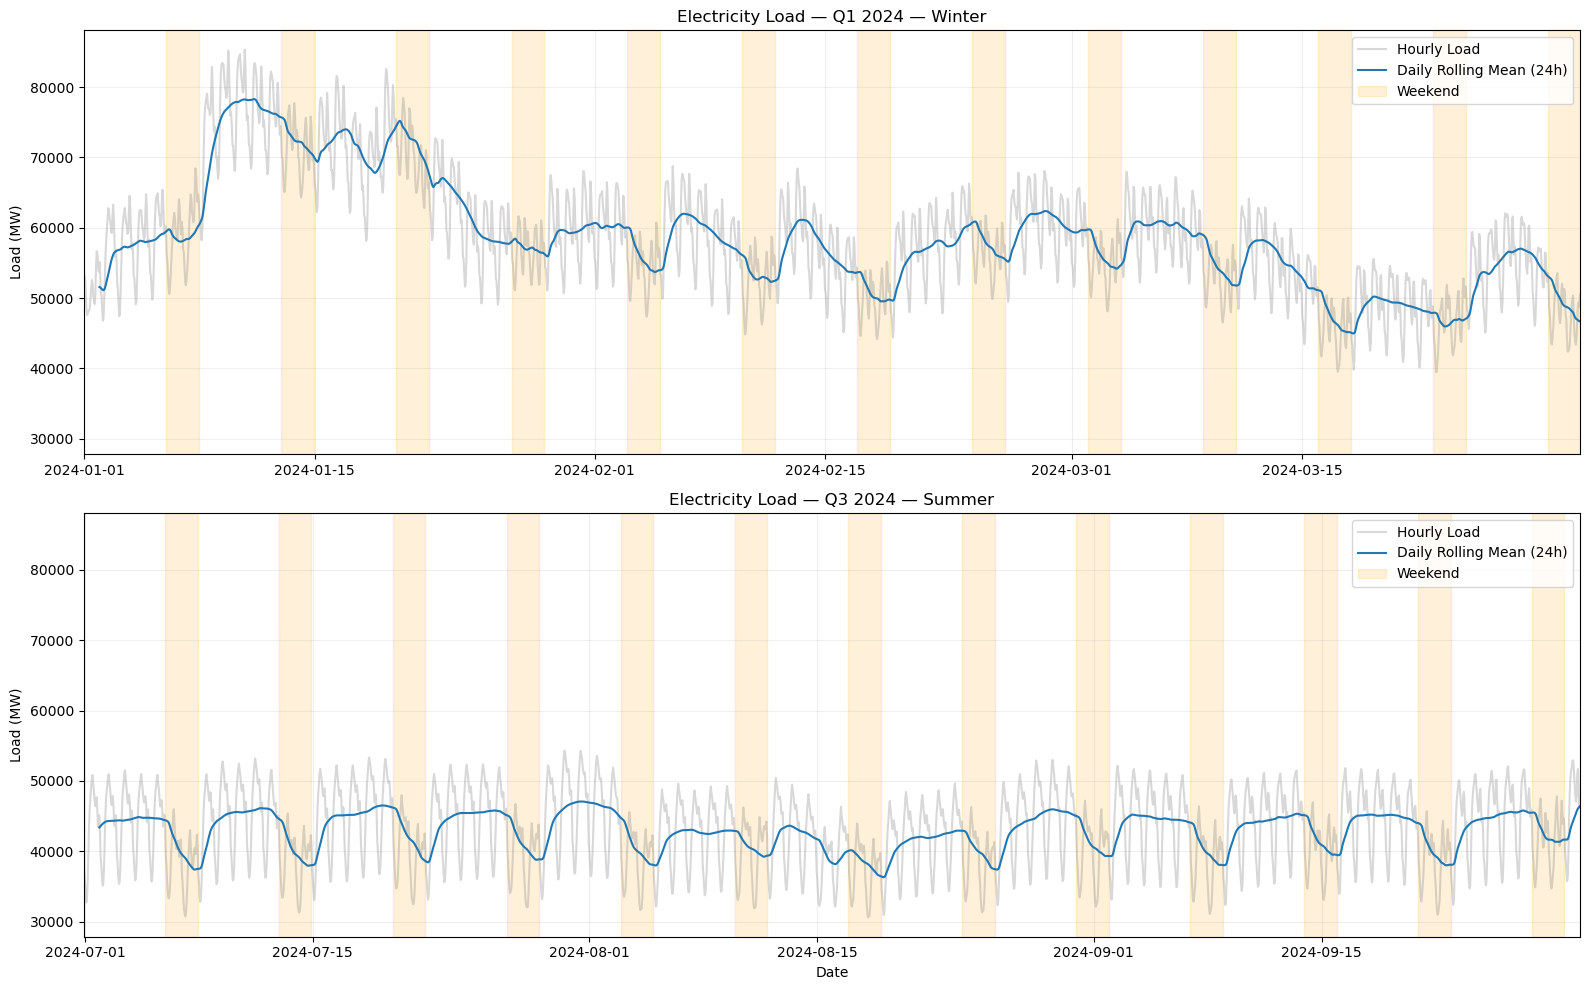

In [10]:
quarters = {
    "Q1 2024 — Winter": ("2024-01-01", "2024-04-01"),
    "Q3 2024 — Summer": ("2024-07-01", "2024-10-01")
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharey=True)

for ax, (label, (start, end)) in zip(axes, quarters.items()):

    # Select quarter using French local time
    local = train["datetime_fr"]

    quarter = train.loc[
        (local >= pd.Timestamp(start, tz="Europe/Paris")) &
        (local < pd.Timestamp(end, tz="Europe/Paris")),
        "load_mw"
    ]

    # Hourly load
    ax.plot(quarter.index, quarter, alpha=0.3,
            color="gray", label="Hourly Load")

    # Rolling means
    ax.plot(quarter.index, quarter.rolling(24).mean(),
            linewidth=1.5, label="Daily Rolling Mean (24h)")

    # Highlight weekends (French local time)
    local_days = pd.date_range(
        start, end, freq="D",
        tz="Europe/Paris", inclusive="left"
    )

    first_weekend = True

    for day in local_days:
        if day.dayofweek == 5:
            weekend_start = day.tz_convert("UTC")
            weekend_end = (day + pd.DateOffset(days=2)).tz_convert("UTC")

            ax.axvspan(
                weekend_start, weekend_end,
                color="orange", alpha=0.15,
                label="Weekend" if first_weekend else None
            )
            first_weekend = False

    ax.set_title(f"Electricity Load — {label}")
    ax.set_ylabel("Load (MW)")
    ax.set_xlim(quarter.index.min(), quarter.index.max())
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

### **Comments** 

- As can be seen in the two graphs, which show a weekday/weekend breakdown for Q1 and Q3, which are winter and summer quarters, respectively it is clear that the decline in consumption is widespread on weekends and that this is not an isolated case from our previous analysis, regardless of annual seasonality. 

- Therefore, national consumption clearly depends on two fundamental factors:

    **1) Economic activity:** The widespread decline is due to the sharp reduction in industrial and economic activity on weekends.

    **2) Individual household activity:** The volume of consumption accounted for by households in France is also a central factor in consumption, particularly when it comes to fine-grained patterns (intraday fluctuations). 

### **Consequently, within an annual cycle, which factor appears to have the greatest impact: a potential widespread decline in economic activity or widespread unemployment ?**

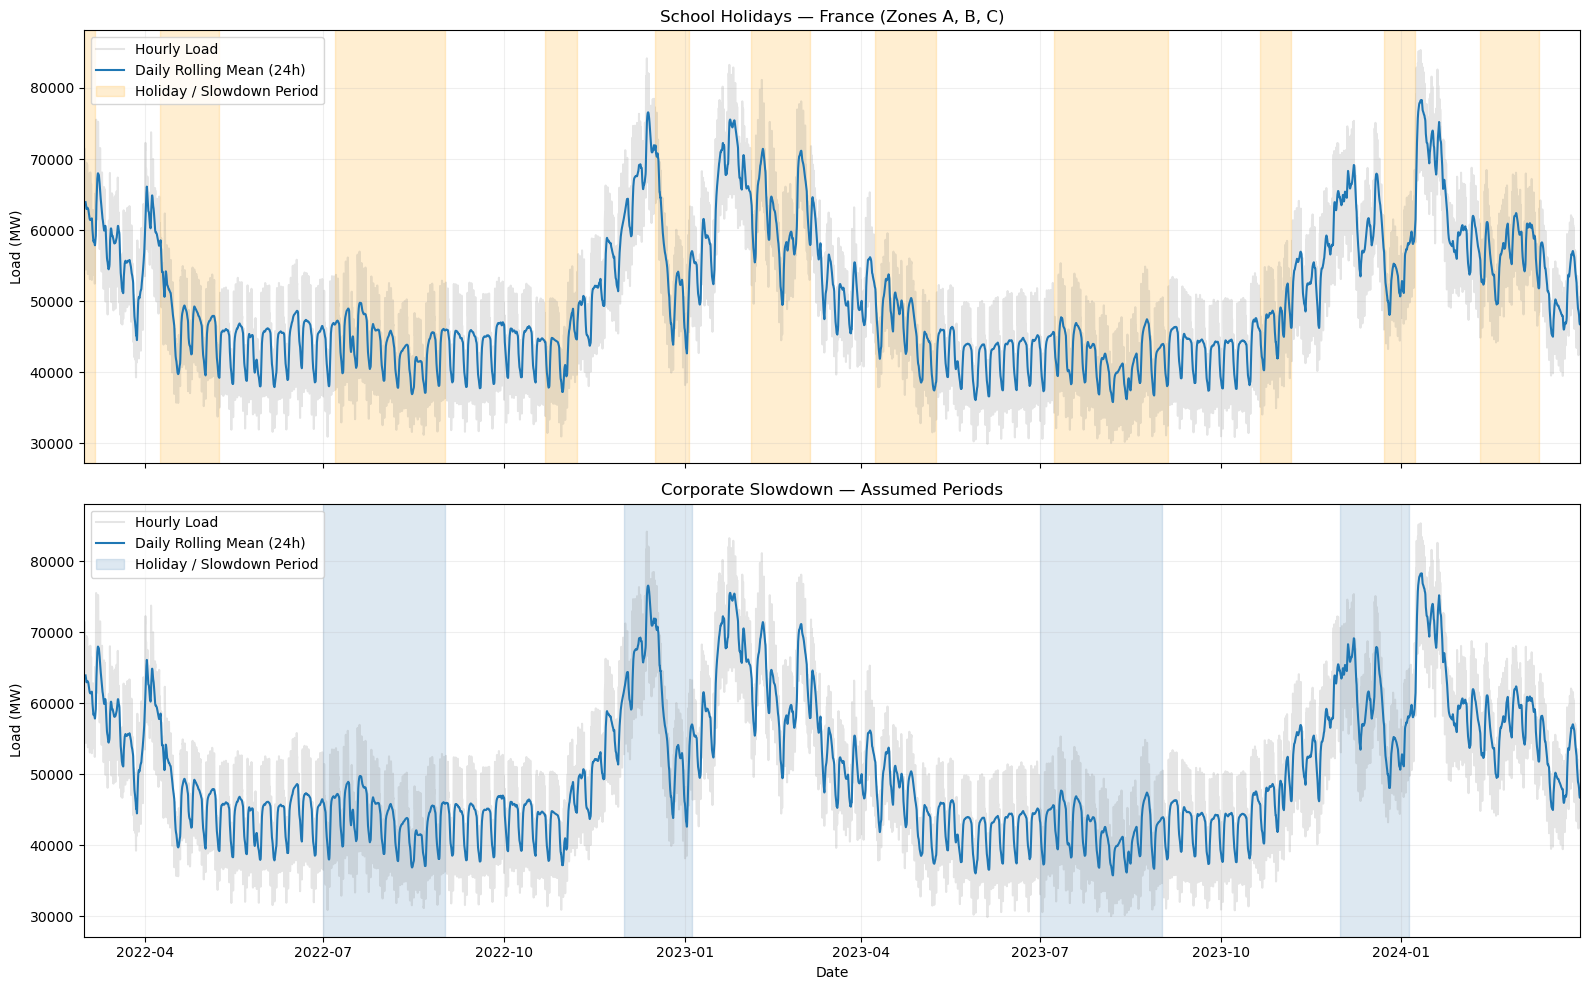

In [11]:
# Period: March 2022 to March 2024
start_date = "2022-03-01"
end_date = "2024-04-01"

start = pd.Timestamp(start_date, tz="Europe/Paris").tz_convert("UTC")
end = pd.Timestamp(end_date, tz="Europe/Paris").tz_convert("UTC")

y = train.loc[(train.index >= start) & (train.index < end), "load_mw"]

# School holidays: at least one zone (A, B, C)
school_holidays = [
    ("2022-03-01", "2022-03-07"),
    ("2022-04-09", "2022-05-09"),
    ("2022-07-07", "2022-09-01"),
    ("2022-10-22", "2022-11-07"),
    ("2022-12-17", "2023-01-03"),
    ("2023-02-04", "2023-03-06"),
    ("2023-04-08", "2023-05-09"),
    ("2023-07-08", "2023-09-04"),
    ("2023-10-21", "2023-11-06"),
    ("2023-12-23", "2024-01-08"),
    ("2024-02-10", "2024-03-11")
]

# Assumed corporate slowdown periods
corporate_holidays = [
    ("2022-07-01", "2022-09-01"),
    ("2022-12-01", "2023-01-05"),
    ("2023-07-01", "2023-09-01"),
    ("2023-12-01", "2024-01-05")
]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True, sharey=True)

studies = [
    ("School Holidays — France (Zones A, B, C)", school_holidays, "orange"),
    ("Corporate Slowdown — Assumed Periods", corporate_holidays, "steelblue")
]

for ax, (title, periods, color) in zip(axes, studies):

    # Hourly consumption
    ax.plot(y.index, y, color="gray", alpha=0.2, label="Hourly Load")

    # Daily rolling mean
    ax.plot(
        y.index,
        y.rolling(24).mean(),
        linewidth=1.5,
        label="Daily Rolling Mean (24h)"
    )

    # Highlight periods using French local dates
    for i, (date_start, date_end) in enumerate(periods):

        t0 = pd.Timestamp(date_start, tz="Europe/Paris").tz_convert("UTC")
        t1 = pd.Timestamp(date_end, tz="Europe/Paris").tz_convert("UTC")

        ax.axvspan(
            t0, t1,
            color=color,
            alpha=0.18,
            label="Holiday / Slowdown Period" if i == 0 else None
        )

    ax.set_title(title)
    ax.set_ylabel("Load (MW)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")
axes[-1].set_xlim(start, end)

plt.tight_layout()
plt.show()

### **Comment :**
- The business holiday chart seems to provide a much more accurate picture of the nationwide decline in consumption that naturally occurs around the winter holidays, which does not allow for a continued slowdown in activity as seen during the summer, a period that also typically sees a trough in July.

--- 
# **2. Baseline Models & RTE Benchmark**

### **2.1 — Forecasting Protocol**

All models follow the same operational forecasting procedure:

- **Forecast origin:** day D at 11:00 (Europe/Paris).
- **Target:** hourly electricity demand from 00:00 to 23:00 on D+1 (French local time).
- **Historical inputs:** observations available strictly before the forecast origin.
- **Time indexing:** UTC for hourly lags, French local time for target definition.
- **Output:** 24 hourly predictions per day.

**Daylight saving transitions:**
- 23-hour day: discard the prediction for the nonexistent 02:00.
- 25-hour day: assign NaN to the first 02:00 occurrence and keep the prediction for the second.

The same rules apply to every model and benchmark.

In [12]:
def get_forecast_window(target_day):

    # French local day D+1
    day = pd.Timestamp(target_day, tz="Europe/Paris")
    next_day = day + pd.DateOffset(days=1)

    # Forecast origin: day D at 11:00 local time
    origin = (day - pd.DateOffset(days=1)).replace(hour=11)

    # Real target timestamps in UTC
    target_hours = pd.date_range(
        start=day,
        end=next_day,
        freq="h",
        inclusive="left"
    ).tz_convert("UTC")

    return origin.tz_convert("UTC"), target_hours

**Test for origin and targeting**

In [13]:
for day in ["2025-01-15", "2025-03-30", "2025-06-26", "2025-10-26", "2025-11-26"]:
    origin, targets = get_forecast_window(day)

    print(
        day,
        "| Origin:", origin,
        "| Target hours:", len(targets)
    )

2025-01-15 | Origin: 2025-01-14 10:00:00+00:00 | Target hours: 24
2025-03-30 | Origin: 2025-03-29 10:00:00+00:00 | Target hours: 23
2025-06-26 | Origin: 2025-06-25 09:00:00+00:00 | Target hours: 24
2025-10-26 | Origin: 2025-10-25 09:00:00+00:00 | Target hours: 25
2025-11-26 | Origin: 2025-11-25 10:00:00+00:00 | Target hours: 24


### **2.2 — Daylight Saving Time Alignment**

Every model produces 24 predictions indexed by French clock hours (0–23).

We align these predictions with real UTC timestamps:

- Normal days: direct alignment.
- Spring transition: missing local hour excluded.
- Autumn transition: first repeated 02:00 assigned NaN.

DST transitions are known in advance, so this adjustment introduces no data leakage.

In [14]:
def align_24h_forecast(predictions, target_hours):

    predictions = np.asarray(predictions)

    if len(predictions) != 24:
        raise ValueError("Expected exactly 24 predictions")

    # French clock hours corresponding to real UTC timestamps
    local_hours = target_hours.tz_convert("Europe/Paris").hour

    # Map each clock hour to its prediction
    aligned = pd.Series(
        predictions[local_hours],
        index=target_hours,
        dtype=float
    )

    # Ignore first occurrence of repeated hours
    duplicate_mask = pd.Index(local_hours).duplicated(keep="last")
    aligned.iloc[np.flatnonzero(duplicate_mask)] = np.nan

    return aligned

for day in ["2025-01-15", "2025-03-30", "2025-10-26"]:

    _, targets = get_forecast_window(day)

    pred = align_24h_forecast(np.arange(24), targets)

    print(
        day,
        "| Predictions:", pred.notna().sum(),
        "| NaN:", pred.isna().sum()
    )

2025-01-15 | Predictions: 24 | NaN: 0
2025-03-30 | Predictions: 23 | NaN: 0
2025-10-26 | Predictions: 24 | NaN: 1


### **2.3 — Naive Forecasts & RTE Benchmark**

We establish three reference forecasts:

- **Naive (48h):** consumption observed 48 hours before the target timestamp.
- **Seasonal Naive (168h):** consumption observed 7 days before the target timestamp.
- **RTE D+1:** official day-ahead demand forecast.

Both naive methods use fixed UTC lags, respecting the 11:00 forecast cutoff.

Predictions are generated day by day using the same forecasting protocol. We initially evaluate them on the **2025 validation period**, keeping 2026 untouched.

In [15]:
baseline_days = []

# All French target dates in the validation set
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

for day in target_days:

    origin, targets = get_forecast_window(day)

    # One prediction per French clock hour (0–23)
    naive_48 = np.full(24, np.nan)
    naive_168 = np.full(24, np.nan)
    naive_720 = np.full(24, np.nan)
    naive_2160 = np.full(24, np.nan)
    rte_24 = np.full(24, np.nan)

    local_hours = targets.tz_convert("Europe/Paris").hour

    # Keep the second occurrence of repeated clock hours
    duplicates = pd.Index(local_hours).duplicated(keep="last")

    for t, hour, duplicate in zip(targets, local_hours, duplicates):

        if duplicate:
            continue

        # Fixed UTC lags
        t48 = t - pd.Timedelta(hours=48)
        t168 = t - pd.Timedelta(hours=168)
        t720 = t - pd.Timedelta(hours=720)
        t2160 = t - pd.Timedelta(hours=2160)

        # Verify forecast-time availability
        assert all(
            lag < origin
            for lag in [t48, t168, t720, t2160]
        )

        naive_48[hour] = df.loc[t48, "load_mw"]
        naive_168[hour] = df.loc[t168, "load_mw"]
        naive_720[hour] = df.loc[t720, "load_mw"]
        naive_2160[hour] = df.loc[t2160, "load_mw"]
        rte_24[hour] = df.loc[t, "rte_forecast_d1_mw"]

    # Align all forecasts with actual timestamps
    daily = pd.DataFrame({
        "actual": df.loc[targets, "load_mw"],
        "naive_48h": align_24h_forecast(naive_48, targets),
        "seasonal_naive_168h": align_24h_forecast(naive_168, targets),
        "monthly_naive_720h": align_24h_forecast(naive_720, targets),
        "quarterly_naive_2160h": align_24h_forecast(naive_2160, targets),
        "rte_d1": align_24h_forecast(rte_24, targets)
    })

    baseline_days.append(daily)

# Reconstruct the complete validation series
baseline_val = pd.concat(baseline_days).sort_index()

display(baseline_val.head())

,actual,naive_48h,seasonal_naive_168h,monthly_naive_720h,quarterly_naive_2160h,rte_d1
2024-12-31 23:00:00+00:00,64637.0,62862.0,56026.0,54322.0,42246.0,62988.0
2025-01-01 00:00:00+00:00,62362.0,59816.0,53536.0,51048.0,41066.0,61375.0
2025-01-01 01:00:00+00:00,61780.0,58802.0,52597.0,49953.0,39241.0,60062.0
2025-01-01 02:00:00+00:00,59824.0,56989.0,50093.0,48176.0,37714.0,56775.0
2025-01-01 03:00:00+00:00,57606.0,55544.0,47504.0,46752.0,38186.0,54550.0


### **2.4 — Evaluation Metrics & Missing Values**

**MAPE (%) is our primary metric** for model selection and hyperparameter tuning.

Since French national electricity demand is strictly positive and far from zero, MAPE provides an interpretable measure of relative forecasting error without denominator instability.

We also report MAE and RMSE for operational interpretation.

**Evaluation rules:**
- Exclude originally missing observations using `df_raw`.
- Exclude the first repeated 02:00 during autumn DST transitions.
- Never evaluate against interpolated ground truth.
- Use identical target timestamps for all models.

The 2026 test set remains reserved for final evaluation.

In [16]:
# Original observations only
valid_actual = df_raw.loc[baseline_val.index, "load_mw"].notna()
valid_rte = df_raw.loc[baseline_val.index, "rte_forecast_d1_mw"].notna()

# Exclude missing original observations
evaluation_mask = valid_actual & valid_rte

baseline_eval = baseline_val.loc[evaluation_mask].copy()

# Exclude DST-related NaNs before evaluation
baseline_eval = baseline_eval.dropna()

# Check missing predictions
print(baseline_eval.isna().sum())

# Missing model predictions must be investigated, not silently dropped
assert baseline_eval.notna().all().all()
assert (baseline_eval["actual"] > 0).all()

print("Evaluated hours:", len(baseline_eval))

actual                   0
naive_48h                0
seasonal_naive_168h      0
monthly_naive_720h       0
quarterly_naive_2160h    0
rte_d1                   0
dtype: int64
Evaluated hours: 8759


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "MAE (MW)": mean_absolute_error(y_true, y_pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_true, y_pred))
    }

models = [
    "naive_48h",
    "seasonal_naive_168h",
    "monthly_naive_720h",
    "quarterly_naive_2160h",
    "rte_d1"
]
results = {}


for model in models:
    results[model] = evaluate_forecast(
        baseline_eval["actual"],
        baseline_eval[model]
    )

baseline_results = pd.DataFrame(results).T

display(baseline_results.sort_values("MAPE (%)").round(2))

,MAPE (%),MAE (MW),RMSE (MW)
rte_d1,2.82,1396.65,1725.79
seasonal_naive_168h,6.43,3460.56,5145.81
naive_48h,8.04,3993.71,5219.24
monthly_naive_720h,12.70,6436.92,8306.45
quarterly_naive_2160h,22.20,11233.58,14317.34


---
# **3. Statistical Models**
### **3.1 Box-Jenkins (1)— Plot & Seasonal Decomposition**
Following the Box-Jenkins methodology, we first examine the structural components of electricity demand using STL (Seasonal-Trend decomposition using LOESS).

We decompose the hourly training series into trend, daily seasonality (24h), and residuals.

The objective is to determine whether the daily seasonal component captures the main fluctuations or whether additional temporal patterns remain unexplained.

**STL Decomposition (24h)**

We apply STL to the hourly electricity demand from 2022 to 2024, using a daily seasonal period of 168 hours.

We try to observe how these components evolve over multiple years


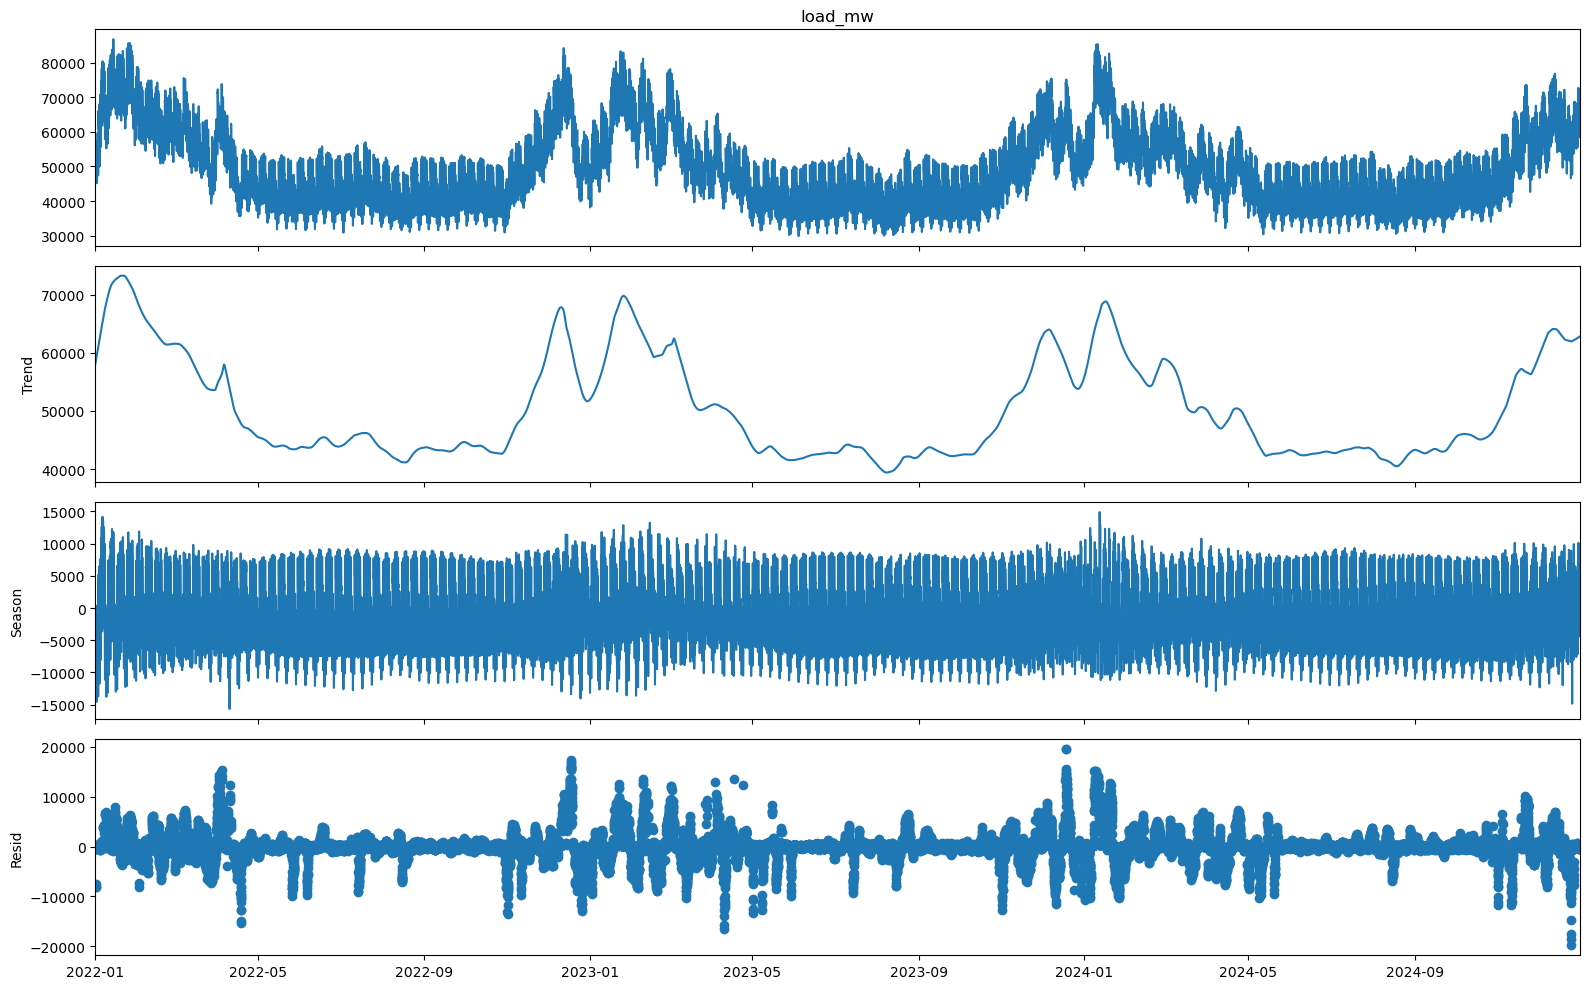

In [18]:
from statsmodels.tsa.seasonal import STL, MSTL

# Select 2022–2024 from training data
y_stl = train.loc["2022-01-01":"2024-12-31", "load_mw"]

# STL decomposition — daily seasonality
stl = STL(y_stl, period=168, robust=True).fit()

# Plot components
fig = stl.plot()
fig.set_size_inches(16, 10)
plt.tight_layout()
plt.show()

**MSTL Decomposition (24h, 168h)**

Daily seasonality (24h): recurring intraday patterns.

Weekly seasonality (168h): recurring weekly consumption patterns.

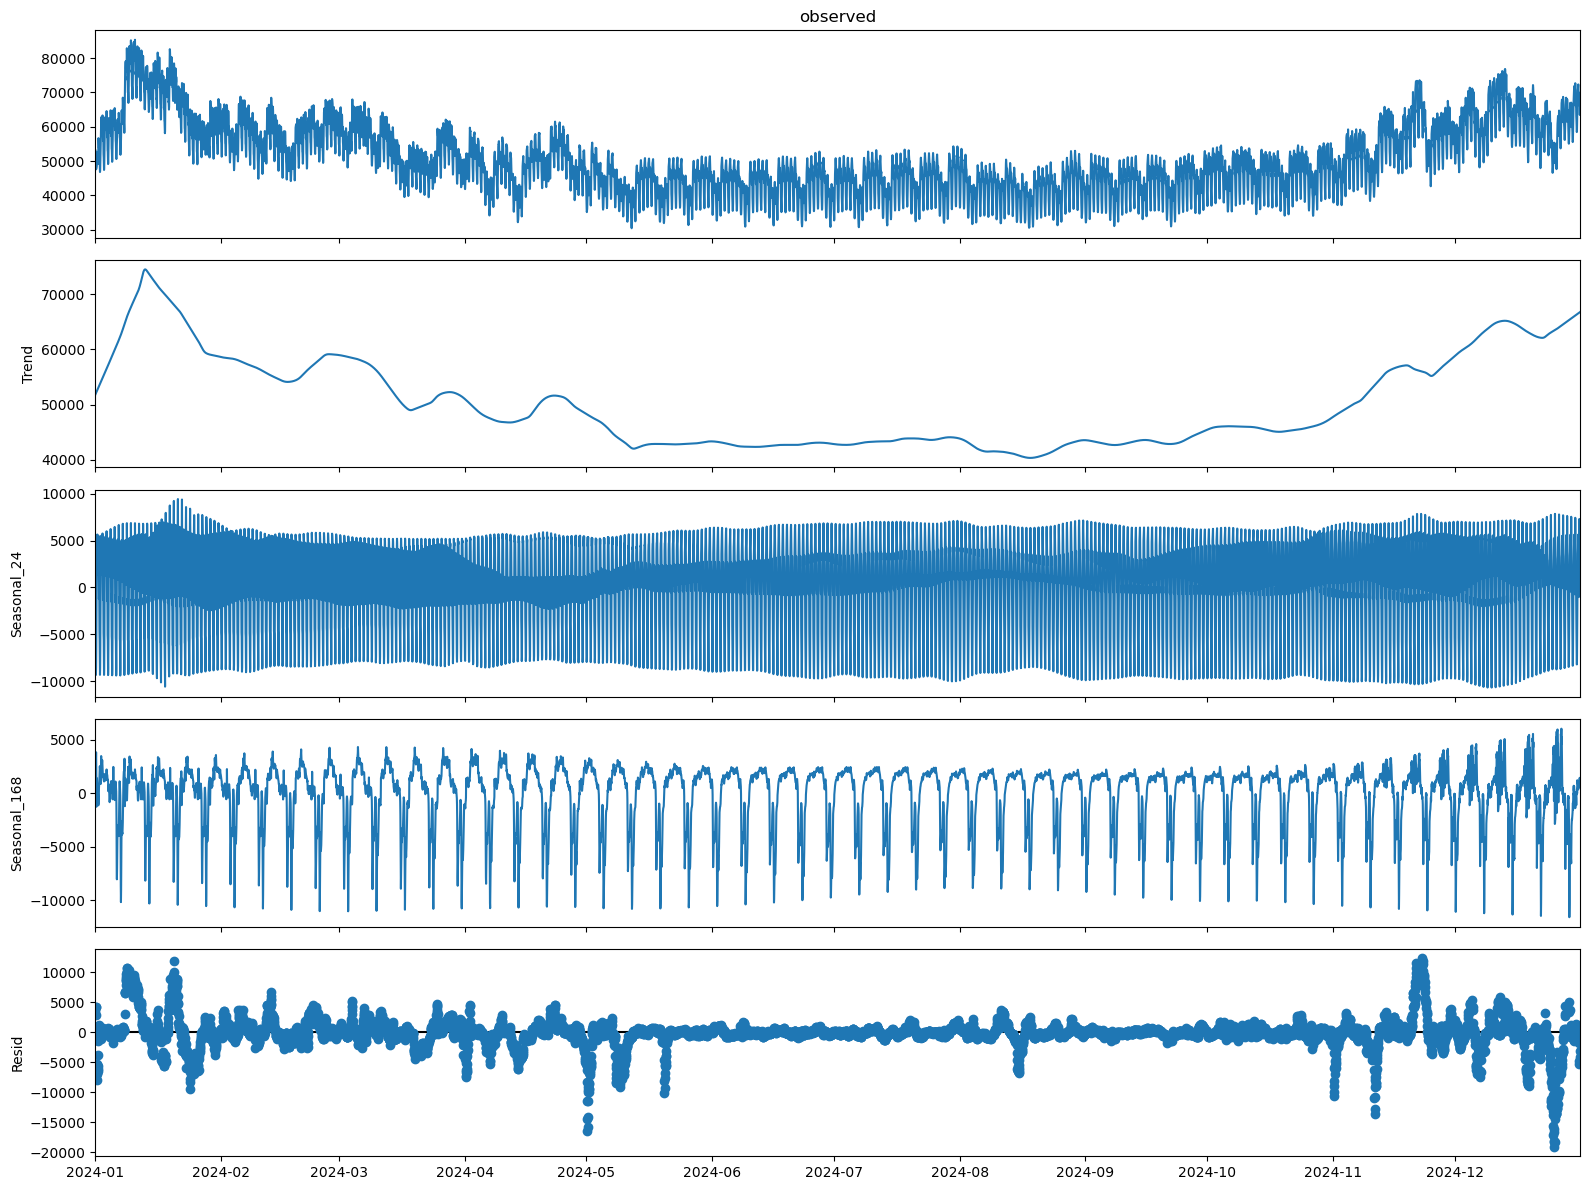

In [19]:
# Select 2024
y_mstl = train.loc["2024-01-01":"2024-12-31", "load_mw"]

# Multiple seasonal decomposition
mstl = MSTL(
    y_mstl,
    periods=(24, 168),
    stl_kwargs={"robust": True}
).fit()

# Plot components
fig = mstl.plot()
fig.set_size_inches(16, 12)
plt.tight_layout()
plt.show()

**Seasonal Comparison**
We compare the daily and weekly seasonal components extracted by MSTL across four representative months of 2024:

- Winter: January
- Spring: April
- Summer: July
- Autumn: October

The objective is to investigate whether the amplitude and variability of daily and weekly consumption patterns change across seasons.

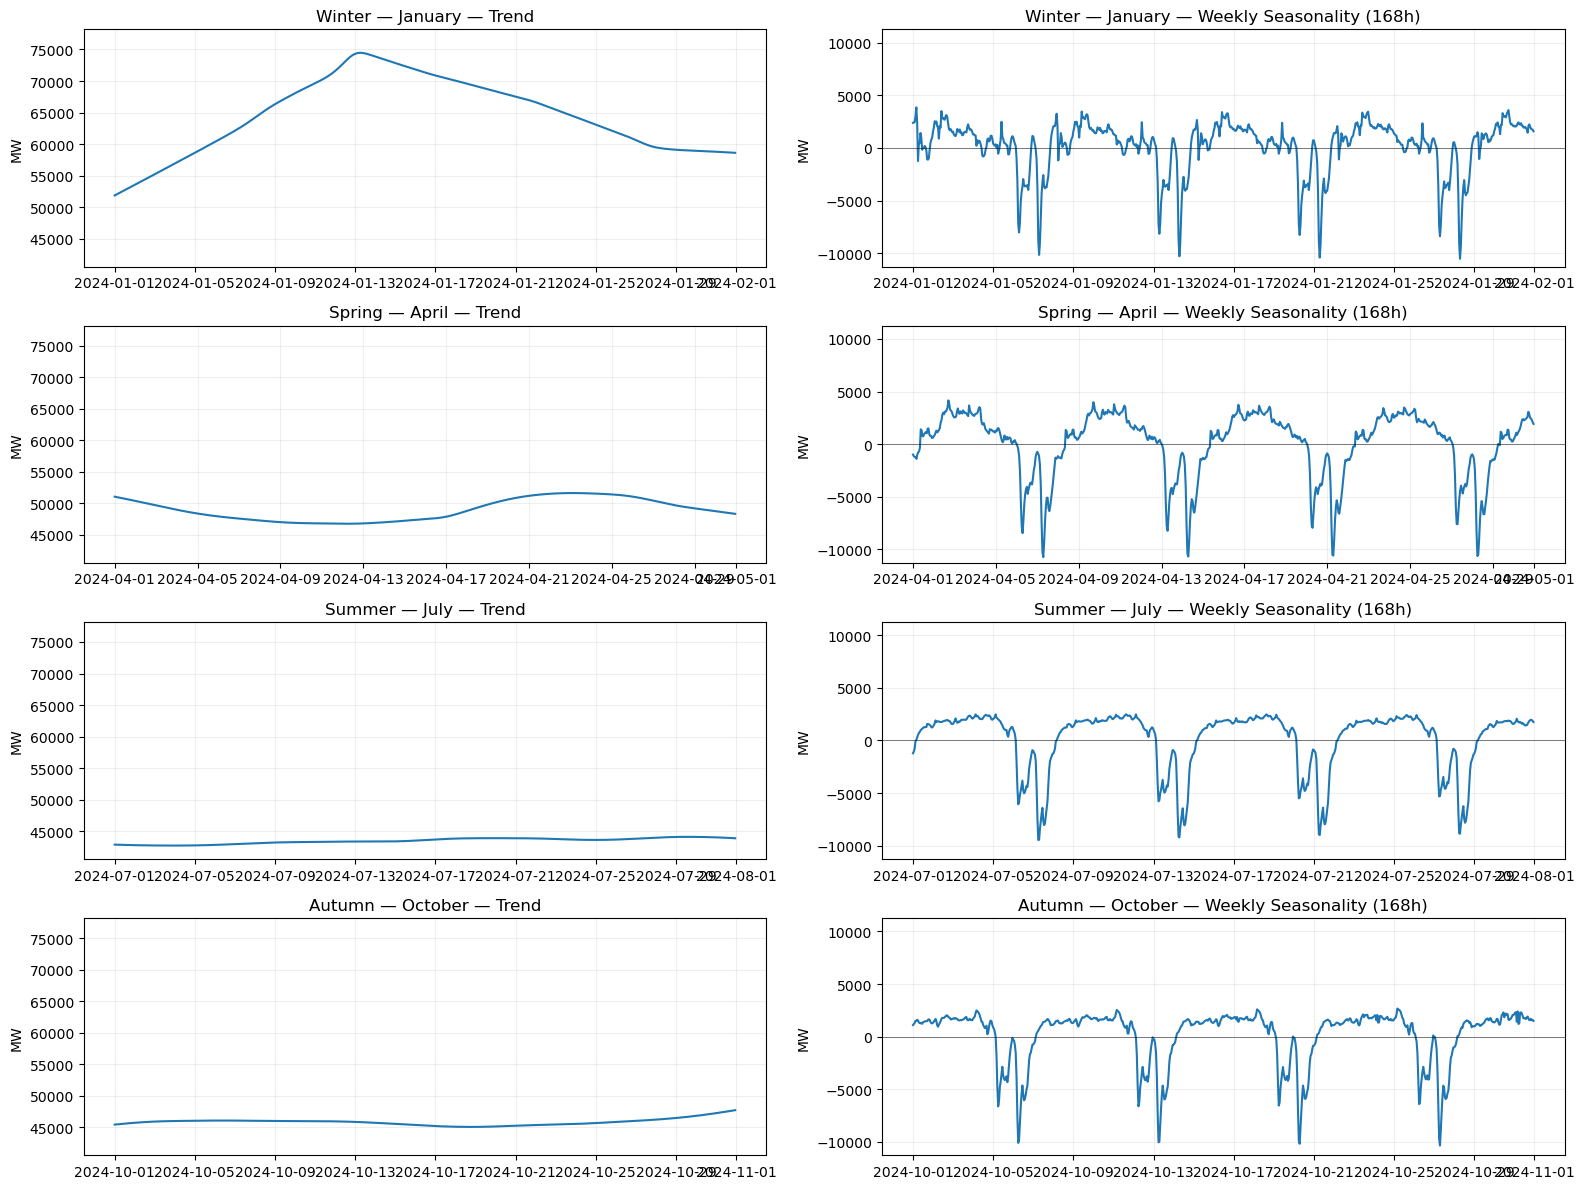

In [20]:
months = {
    "Winter — January": "2024-01",
    "Spring — April": "2024-04",
    "Summer — July": "2024-07",
    "Autumn — October": "2024-10"
}

fig, axes = plt.subplots(4, 2, figsize=(16, 12))

for i, (season, month) in enumerate(months.items()):

    # Trend
    trend = mstl.trend.loc[month]
    axes[i, 0].plot(trend.index, trend.values)
    axes[i, 0].set_title(f"{season} — Trend")
    axes[i, 0].set_ylabel("MW")
    axes[i, 0].grid(alpha=0.2)

    # Weekly seasonality
    weekly = mstl.seasonal["seasonal_168"].loc[month]
    axes[i, 1].plot(weekly.index, weekly.values)
    axes[i, 1].set_title(f"{season} — Weekly Seasonality (168h)")
    axes[i, 1].set_ylabel("MW")
    axes[i, 1].grid(alpha=0.2)

# Common Y-axis for each column
trend_min = min(mstl.trend.loc[m].min() for m in months.values())
trend_max = max(mstl.trend.loc[m].max() for m in months.values())

weekly_max = max(
    mstl.seasonal["seasonal_168"].loc[m].abs().max()
    for m in months.values()
)

for i in range(4):
    axes[i, 0].set_ylim(trend_min * 0.95, trend_max * 1.05)
    axes[i, 1].set_ylim(-weekly_max * 1.05, weekly_max * 1.05)
    axes[i, 1].axhline(0, color="black", linewidth=0.7, alpha=0.5)

plt.tight_layout()
plt.show()

**Quantifying Seasonal Amplitude**

In [21]:
seasonal_stats = []

for season, month in months.items():

    daily = mstl.seasonal["seasonal_24"].loc[month]
    weekly = mstl.seasonal["seasonal_168"].loc[month]

    seasonal_stats.append({
        "Season": season,
        "Daily Std (MW)": daily.std(),
        "Weekly Std (MW)": weekly.std(),
        "Daily Range (MW)": daily.max() - daily.min(),
        "Weekly Range (MW)": weekly.max() - weekly.min()
    })

seasonal_stats = pd.DataFrame(seasonal_stats).set_index("Season")

display(seasonal_stats.round(2))

,Daily Std (MW),Weekly Std (MW),Daily Range (MW),Weekly Range (MW)
Season,,,,
Winter — January,4794.40,2510.56,20033.73,14382.64
Spring — April,4056.27,3086.40,14453.59,14888.09
Summer — July,5170.29,2860.38,17144.77,11928.93
Autumn — October,4946.92,2602.47,16519.01,13013.36


### **3.2 Box-Jenkins (2) - Transform**

we need to assess whether the electricity demand series is stationary.


A stationary time series has statistical properties, such as its mean, variance and autocovariance structure, that do not change over time.
We apply two complementary statistical tests:
- Augmented Dickey-Fuller (ADF) Test :

    H₀: The series has a unit root (non-stationary).

    H₁: The series has no unit root (stationary under the test assumptions).

    Desired result: p-value < 0.05, allowing us to reject H₀.

In [22]:
from statsmodels.tsa.stattools import adfuller, kpss

# Select 2024 training observations
y = train.loc["2022-01-01":"2022-12-31", "load_mw"].dropna()
# y = train["load_mw"].dropna()
# ADF test
adf_result = adfuller(y, autolag="AIC")

print("Augmented Dickey-Fuller Test")
print(f"Statistic: {adf_result[0]:.4f}")
print(f"p-value:   {adf_result[1]:.4f}")


Augmented Dickey-Fuller Test
Statistic: -3.5969
p-value:   0.0058


- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test

    H₀: The series is stationary around a constant level (regression="c").

    H₁: The series is not level-stationary.

    Desired result: p-value > 0.05, meaning we do not reject H₀.

Combining both tests provides complementary evidence about stationarity. However, neither test alone guarantees that the series is stationary, particularly in the presence of complex seasonal patterns.

In [23]:

# KPSS test
kpss_result = kpss(y, regression="c", nlags="auto")

print("\nKPSS Test")
print(f"Statistic: {kpss_result[0]:.4f}")
print(f"p-value:   {kpss_result[1]:.4f}")


KPSS Test
Statistic: 5.0507
p-value:   0.0100


/var/folders/_6/z1319f7x2wx1sh3x189jdmyc0000gn/T/ipykernel_28006/3966449262.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


**Differencing**

Malheuresuement le test KPSS ne confirme pas du tout une série stationnaire 

In [24]:

y = train.loc["2024-01-01":"2024-12-31", "load_mw"].dropna()

transformations = {
    "Original": y,
    "Diff(1)": y.diff(),
    "Diff(1) + Diff(1)": y.diff().diff(),
    "Diff(24)": y.diff(24),
    "Diff(168)": y.diff(168),
    "Diff(1) + Diff(24)": y.diff().diff(24),
    "Diff(1) + Diff(168)": y.diff().diff(168)
}

results = []

for name, series in transformations.items():

    series = series.dropna()

    adf = adfuller(series, autolag="AIC")
    kp = kpss(series, regression="c", nlags="auto")

    results.append({
        "Transformation": name,
        "ADF Statistic": adf[0],
        "ADF p-value": adf[1],
        "KPSS Statistic": kp[0],
        "KPSS p-value": kp[1],
        "ADF Reject H0": adf[1] < 0.05,
        "KPSS Reject H0": kp[1] < 0.05,
        "Stationarity Supported": (adf[1] < 0.05) and (kp[1] > 0.05)
    })

stationarity_results = pd.DataFrame(results).set_index("Transformation")

display(stationarity_results.round(4))

/var/folders/_6/z1319f7x2wx1sh3x189jdmyc0000gn/T/ipykernel_28006/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/_6/z1319f7x2wx1sh3x189jdmyc0000gn/T/ipykernel_28006/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/_6/z1319f7x2wx1sh3x189jdmyc0000gn/T/ipykernel_28006/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/_6/z1319f7x2wx1sh3x189jdmyc0000gn/T/ipykernel_28006/4112654464.py:20: InterpolationWarn

,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,ADF Reject H0,KPSS Reject H0,Stationarity Supported
Transformation,,,,,,,
Original,-4.0962,0.001,3.5129,0.0100,True,True,False
Diff(1),-15.4218,0.000,0.0346,0.1000,True,False,True
Diff(1) + Diff(1),-28.1401,0.000,0.1113,0.1000,True,False,True
Diff(24),-16.1335,0.000,0.0493,0.1000,True,False,True
Diff(168),-6.5838,0.000,0.4869,0.0446,True,True,False
Diff(1) + Diff(24),-18.8213,0.000,0.0025,0.1000,True,False,True
Diff(1) + Diff(168),-15.7016,0.000,0.0284,0.1000,True,False,True


The original series shows conflicting stationarity test results: ADF rejects the unit-root hypothesis, while KPSS rejects level stationarity.

Most differencing transformations provide evidence consistent with stationarity, except for the weekly seasonal difference (168h) applied alone.

Since both first-order differencing and daily seasonal differencing (24h) satisfy the two tests independently, additional differencing may be unnecessary.

We will examine the ACF and PACF of these candidate transformed series to assess their remaining temporal dependence and guide the selection of SARIMA orders while avoiding over-differencing.

### **3.3 Box-Jenkins (2) — Identify: ACF & PACF**

Following the stationarity tests, we focus on two candidate transformations:

- First-order differencing: (d=1,\ D=0).
- Daily seasonal differencing: (d=0,\ D=1,\ s=24).

We examine the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) of each transformed series to identify potential non-seasonal AR/MA orders ((p,q)) and seasonal AR/MA orders ((P,Q)).

In [25]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
import time
import warnings

# Training data
y_fit = train.loc["2024-01-01":"2024-12-31", "load_mw"].asfreq("h")

# Persistent results
aic_results = []
best_models = {}
best_aic = {}

**Diff(1)**

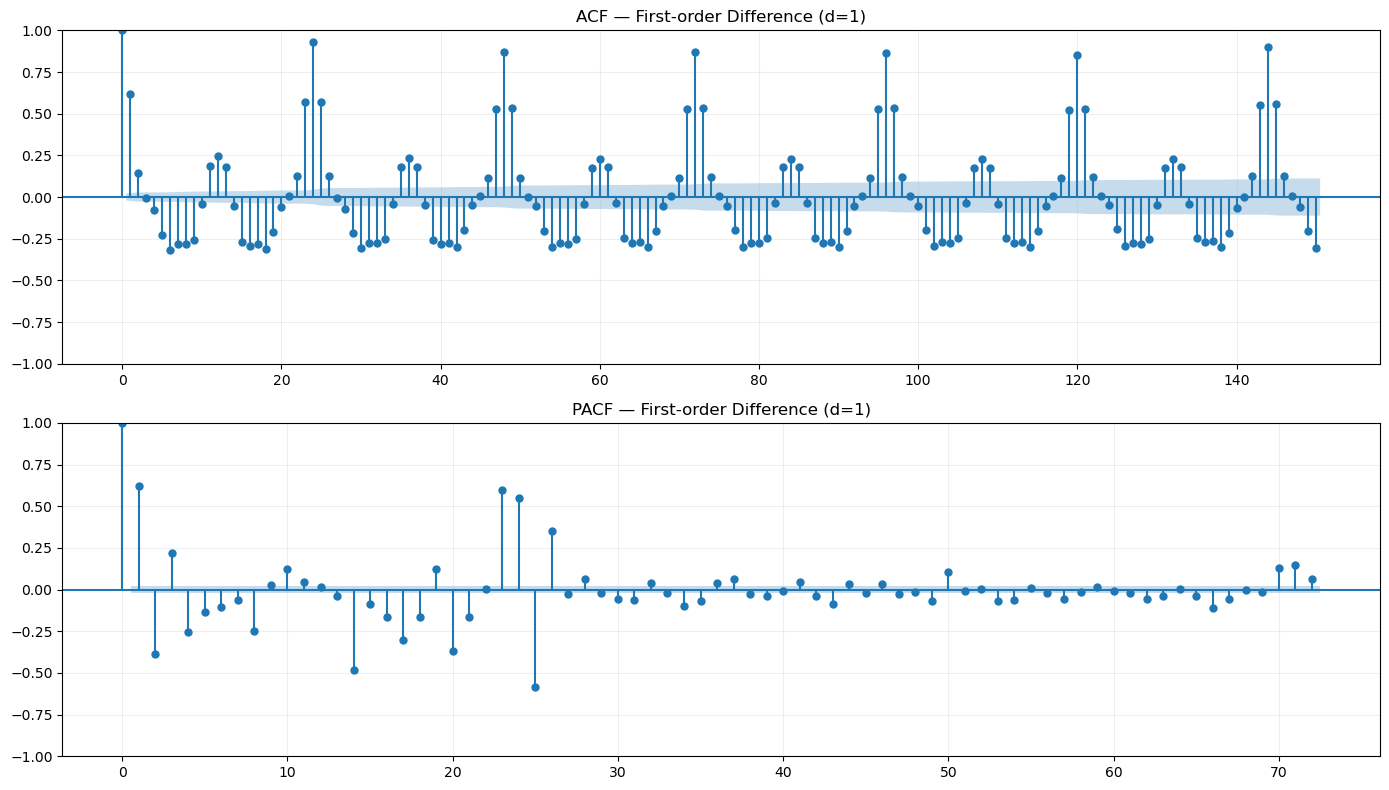

In [26]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# First-order differencing
y_diff1 = y.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff1, lags=150, ax=axes[0])
axes[0].set_title("ACF — First-order Difference (d=1)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff1, lags=72, ax=axes[1], method="ywm")
axes[1].set_title("PACF — First-order Difference (d=1)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [27]:

candidates = {
"Diff(1)": [
        ((2, 1, 1), (1, 0, 1, 24)),# 11 s ? 
        ((2, 1, 2), (1, 0, 1, 24)),#10s
        ((3, 1, 1), (1, 0, 2, 24)),# 143s 
        ((3, 1, 2), (1, 0, 2, 24)),# 138s 
        ((3, 1, 2), (2, 0, 2, 24)),#160s
        ((2, 1, 1), (2, 0, 2, 24)) #130s
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=10)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )


========== Diff(1) ==========

[1/6] START SARIMA(2, 1, 1)x(1, 0, 1, 24)
[1/6] DONE | AIC=145438.84 | Converged=False | Time=8.1s

[2/6] START SARIMA(2, 1, 2)x(1, 0, 1, 24)
[2/6] DONE | AIC=145127.61 | Converged=False | Time=10.0s

[3/6] START SARIMA(3, 1, 1)x(1, 0, 2, 24)
[3/6] DONE | AIC=145307.29 | Converged=False | Time=42.0s

[4/6] START SARIMA(3, 1, 2)x(1, 0, 2, 24)


KeyboardInterrupt: 

**Outcome Diff(1)** :

- p : [0,1,2,3,4]
- q : [0,1,2,3]
- P : [0,1,2]
- Q : [1,2,3]
- s : 24

diff_(1)= {((2, 1, 1), (1, 0, 1, 24))
            ((2, 1, 2), (1, 0, 1, 24))
            ((3, 1, 1), (1, 0, 2, 24))
            ((3, 1, 2), (1, 0, 2, 24))
            ((3, 1, 2), (2, 0, 2, 24))
            ((2, 1, 1), (2, 0, 2, 24))}

**Diff(24)**

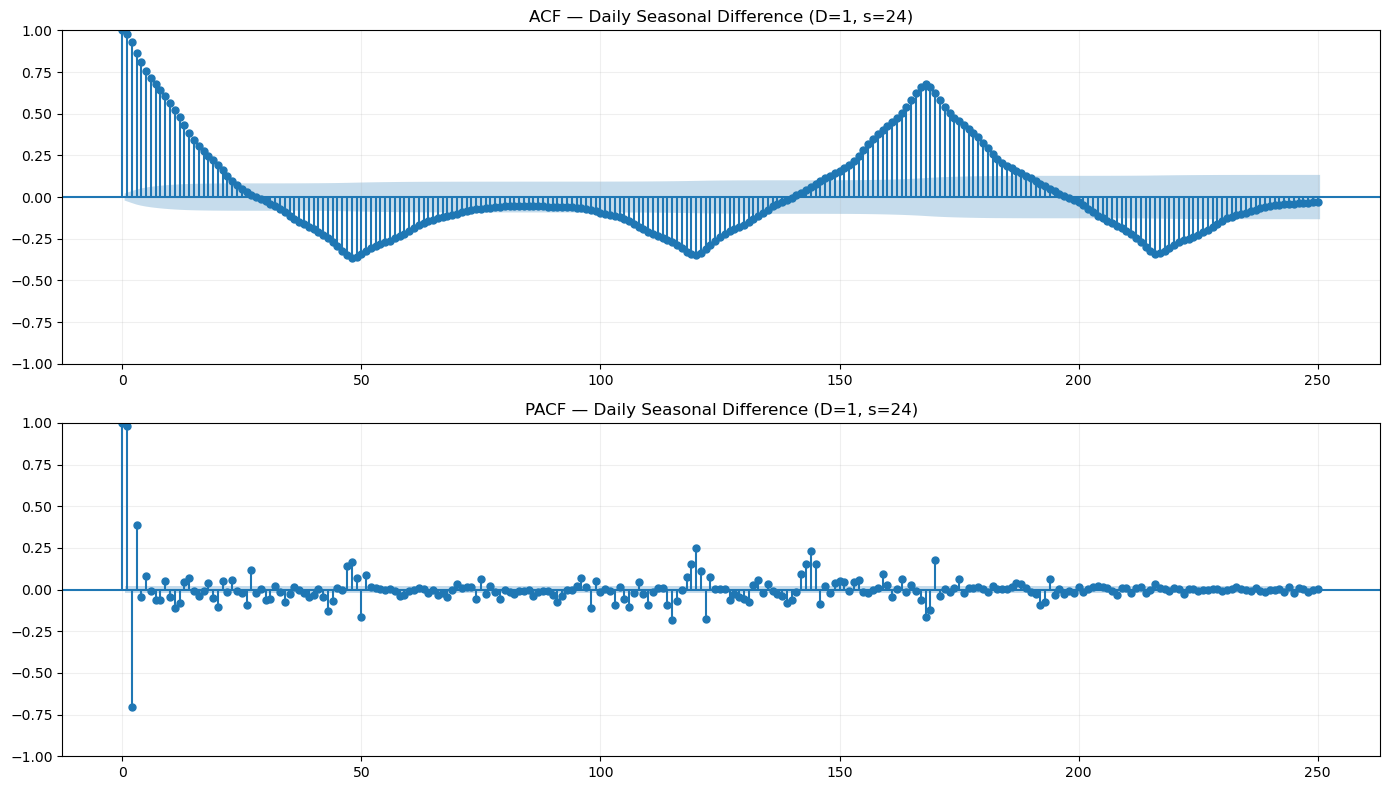

In [28]:
# Daily seasonal differencing
y_diff24 = y.diff(24).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff24, lags=250, ax=axes[0])
axes[0].set_title("ACF — Daily Seasonal Difference (D=1, s=24)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff24, lags=250, ax=axes[1], method="ywm")
axes[1].set_title("PACF — Daily Seasonal Difference (D=1, s=24)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [29]:
candidates = {
"Diff(1)": [
        ((2, 0, 5), (0, 1, 0, 24)),
        ((4, 0, 5), (0, 1, 0, 24)),
        ((3, 0, 1), (0, 1, 0, 24)),
        ((3, 0, 2), (0, 1, 0, 24)),
        ((3, 0, 3), (0, 1, 0, 24)),#
        ((3, 0, 0), (0, 1, 0, 24)),
        ((0, 0, 3), (0, 1, 0, 24)),
        ((0, 0, 1), (0, 1, 0, 24)),
        ((1, 0, 0), (0, 1, 0, 24)),
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=50)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )


========== Diff(1) ==========

[1/9] START SARIMA(2, 0, 5)x(0, 1, 0, 24)
[1/9] DONE | AIC=136178.91 | Converged=False | Time=19.5s

[2/9] START SARIMA(4, 0, 5)x(0, 1, 0, 24)
[2/9] DONE | AIC=135969.29 | Converged=False | Time=25.0s

[3/9] START SARIMA(3, 0, 1)x(0, 1, 0, 24)
[3/9] DONE | AIC=136177.30 | Converged=True | Time=6.3s

[4/9] START SARIMA(3, 0, 2)x(0, 1, 0, 24)
[4/9] DONE | AIC=136157.31 | Converged=True | Time=8.1s

[5/9] START SARIMA(3, 0, 3)x(0, 1, 0, 24)
[5/9] DONE | AIC=136155.52 | Converged=True | Time=11.4s

[6/9] START SARIMA(3, 0, 0)x(0, 1, 0, 24)
[6/9] DONE | AIC=136230.88 | Converged=True | Time=4.4s

[7/9] START SARIMA(0, 0, 3)x(0, 1, 0, 24)
[7/9] DONE | AIC=146083.30 | Converged=True | Time=29.8s

[8/9] START SARIMA(0, 0, 1)x(0, 1, 0, 24)
[8/9] DONE | AIC=157596.19 | Converged=True | Time=4.0s

[9/9] START SARIMA(1, 0, 0)x(0, 1, 0, 24)
[9/9] DONE | AIC=143453.68 | Converged=True | Time=1.0s


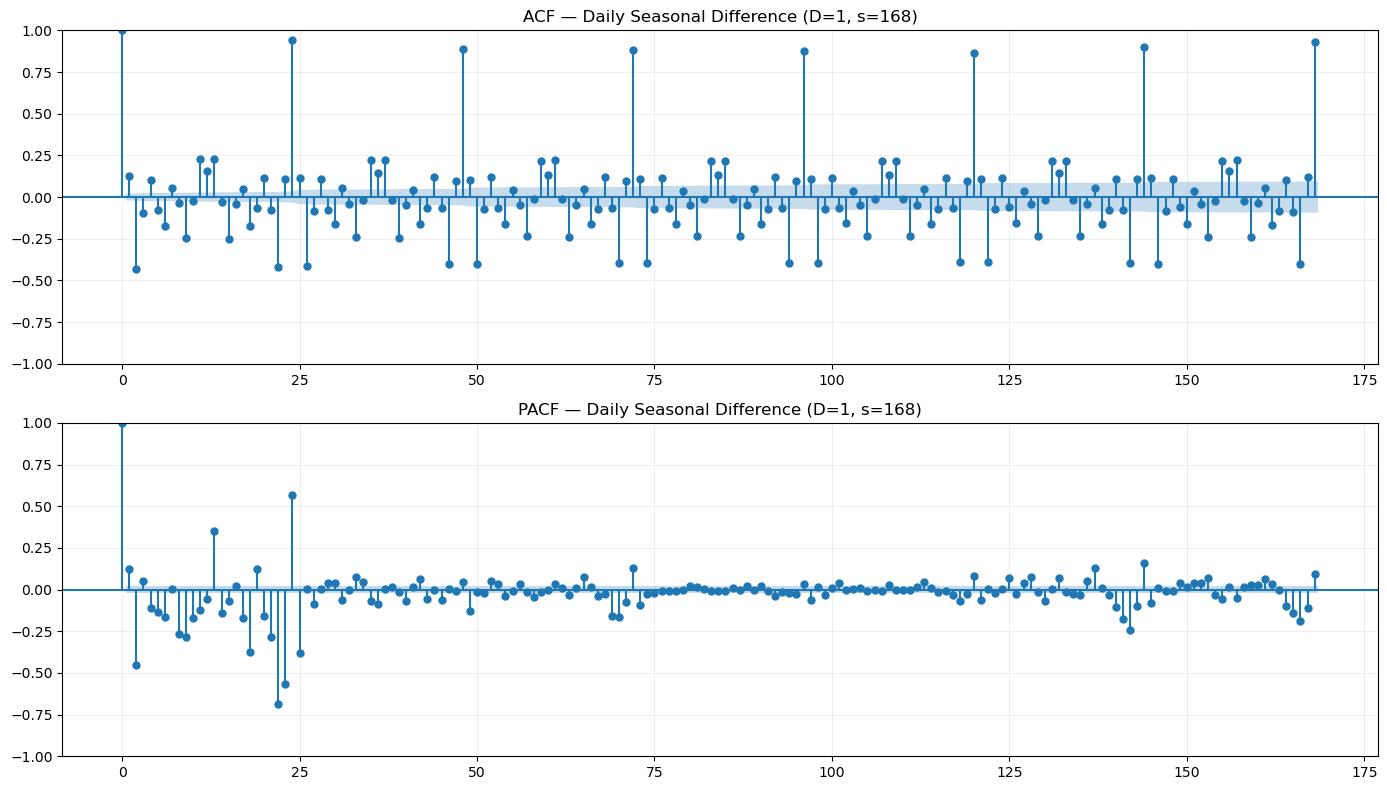

In [30]:
# Daily seasonal differencing
y_diff24 = y.diff().diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff24, lags=168, ax=axes[0])
axes[0].set_title("ACF — Daily Seasonal Difference (D=1, s=168)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff24, lags=168, ax=axes[1], method="ywm")
axes[1].set_title("PACF — Daily Seasonal Difference (D=1, s=168)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:

candidates = {
"Diff_24": [
        ((2, 0, 7), (1, 1, 0, 24)),
        ((3, 0, 2), (0, 1, 0, 24)),
        ((3, 0, 7), (1, 1, 0, 24)),
        ((1, 0, 0), (0, 1, 0, 24))
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=50)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )

### **3.4 Box-Jenkins (4) — Model Estimation and AIC Comparison**

We investigate three differencing configurations:

- Ordinary differencing: (d=1,\ D=0,\ s=24).

- Daily seasonal differencing: (d=0,\ D=1,\ s=24).

- Combined ordinary and weekly seasonal differencing: (d=1,\ D=1,\ s=168).

**AIC, MLE, complexité et convergence**

In [31]:
aic_df = pd.DataFrame(aic_results)

display(
    aic_df.sort_values(["Family", "AIC"]).round(2)
)

,Family,Order,Seasonal Order,Log-Likelihood,k,AIC,Converged,Time (s)
4,Diff(1),"(4, 0, 5)","(0, 1, 0, 24)",-67974.65,10,135969.29,False,25.01
7,Diff(1),"(3, 0, 3)","(0, 1, 0, 24)",-68070.76,7,136155.52,True,11.37
6,Diff(1),"(3, 0, 2)","(0, 1, 0, 24)",-68072.65,6,136157.31,True,8.12
5,Diff(1),"(3, 0, 1)","(0, 1, 0, 24)",-68083.65,5,136177.30,True,6.34
3,Diff(1),"(2, 0, 5)","(0, 1, 0, 24)",-68081.46,8,136178.91,False,19.51
8,Diff(1),"(3, 0, 0)","(0, 1, 0, 24)",-68111.44,4,136230.88,True,4.40
11,Diff(1),"(1, 0, 0)","(0, 1, 0, 24)",-71724.84,2,143453.68,True,1.00
1,Diff(1),"(2, 1, 2)","(1, 0, 1, 24)",-72556.80,7,145127.61,False,9.97
2,Diff(1),"(3, 1, 1)","(1, 0, 2, 24)",-72645.64,8,145307.29,False,42.01
0,Diff(1),"(2, 1, 1)","(1, 0, 1, 24)",-72713.42,6,145438.84,False,8.12


In [32]:
# Best converged model per family
best_converged = (
    aic_df[aic_df["Converged"]]
    .sort_values("AIC")
    .groupby("Family")
    .head(1)
)

# Top 2 AIC models per family, regardless of convergence
best_aic_top2 = (
    aic_df[np.isfinite(aic_df["AIC"])]
    .sort_values("AIC")
    .groupby("Family")
    .head(2)
)

# Combine selections and remove duplicates
best_results = (
    pd.concat([best_converged, best_aic_top2])
    .drop_duplicates(subset=["Family", "Order", "Seasonal Order"])
    .sort_values(["Family", "AIC"])
    .reset_index(drop=True)
)

display(best_results)

,Family,Order,Seasonal Order,Log-Likelihood,k,AIC,Converged,Time (s)
0,Diff(1),"(4, 0, 5)","(0, 1, 0, 24)",-67974.646422,10,135969.292843,False,25.006204
1,Diff(1),"(3, 0, 3)","(0, 1, 0, 24)",-68070.758112,7,136155.516225,True,11.369096


### **3.5 Box-Jenkins (5) — Verification: Residual Diagnostics**

Following AIC-based model selection, we examine the residuals of the best converged SARIMA model from each differencing family.

A well-specified forecasting model should leave residuals with no significant remaining autocorrelation.

We investigate:

**Residual time plots:** identify persistent patterns, outliers and changing variance.

**Residual ACF:** detect remaining daily and weekly autocorrelation.

**Ljung-Box test:** assess whether residual autocorrelations are jointly zero.

For the Ljung-Box test:

H₀: All residual autocorrelations up to the tested lag are zero.

H₁: At least one residual autocorrelation is nonzero.

Desired result: p-value > 0.05, meaning we do not reject H₀.

**Residual time plots:**

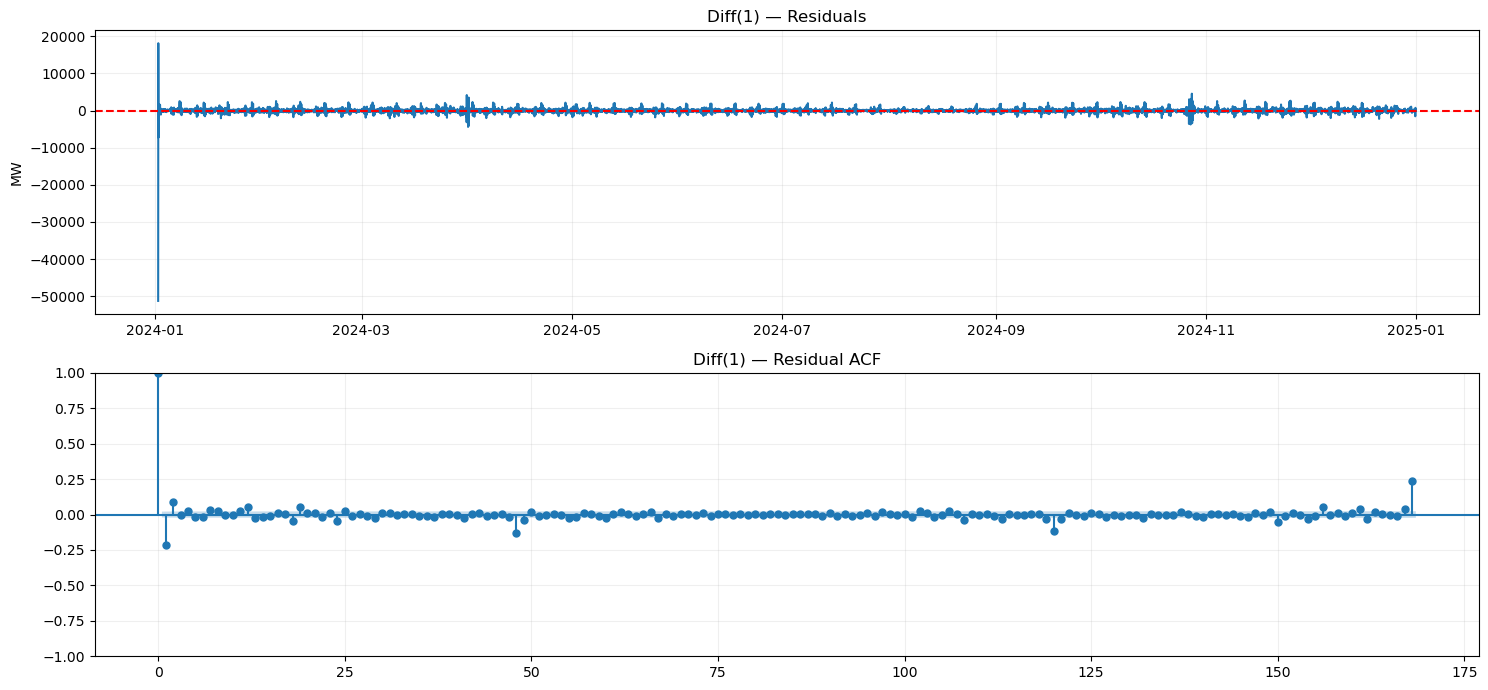

In [33]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for family, result in best_models.items():

    # Discard initialization observations
    burn = result.loglikelihood_burn
    resid = result.resid.iloc[burn:].dropna()

    fig, axes = plt.subplots(2, 1, figsize=(15, 7))

    axes[0].plot(resid.index, resid)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_title(f"{family} — Residuals")
    axes[0].set_ylabel("MW")
    axes[0].grid(alpha=0.2)

    plot_acf(resid, lags=168, ax=axes[1])
    axes[1].set_title(f"{family} — Residual ACF")
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

**Ljung-Box Test**

In [34]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_results = []

for family, result in best_models.items():

    burn = result.loglikelihood_burn
    resid = result.resid.iloc[burn:].dropna()

    lb = acorr_ljungbox(
        resid,
        lags=[1, 24],
        model_df=0,
        return_df=True
    )

    for lag, row in lb.iterrows():
        ljung_results.append({
            "Family": family,
            "Lag": lag,
            "LB Statistic": row["lb_stat"],
            "p-value": row["lb_pvalue"],
            "Reject H0": row["lb_pvalue"] < 0.05
        })

ljung_results = pd.DataFrame(ljung_results)

display(ljung_results.round(4))

,Family,Lag,LB Statistic,p-value,Reject H0
0,Diff(1),1,394.4535,0.0,True
1,Diff(1),24,590.9552,0.0,True


### Residual Diagnostics — Conclusion

The AIC-selected SARIMA models are evaluated using residual plots, autocorrelation diagnostics and Ljung-Box tests at daily (24h) and weekly (168h) lags.

Models displaying significant residual autocorrelation may have failed to capture important temporal dependencies, even when their AIC is relatively low.

These diagnostics will be considered when retaining candidates for day-ahead forecasting validation.

### **3.6 Box-Jenkins (6) — Forecast with Confident Intervals**


After model estimation and residual verification, we evaluate the retained SARIMA candidates under the operational day-ahead forecasting protocol.

For each forecast origin:

- Forecast origin: 11:00 Europe/Paris on day D.

- Target: All 24 local clock-hour slots of day D+1.

- Information cutoff: No observations at or after the forecast origin may be used.

- DST handling: Apply the previously defined alignment and evaluation rules.

- Each model produces point forecasts and 95% prediction intervals.

In [35]:
# Selected SARIMA models from Step 4
selected_models = {}

for family, result in best_models.items():

    selected_models[family] = {
        "order": result.model.order,
        "seasonal_order": result.model.seasonal_order,
        "AIC": result.aic
    }

selected_models_df = pd.DataFrame(selected_models).T

display(selected_models_df)

,order,seasonal_order,AIC
Diff(1),"(3, 0, 3)","(0, 1, 0, 24)",136155.516225


**Test - Forecast D+1 before 12 a.m. avec intervalle à 95 %**

In [36]:
# Select one fitted SARIMA
family = next(iter(best_models))
result = best_models[family]

# First safe validation target day
target_day = "2025-01-02"

origin, targets = get_forecast_window(target_day)

# Use only observations strictly before the forecast origin
last_train_time = result.model.data.row_labels[-1]
new_times = pd.date_range(
    last_train_time + pd.Timedelta(hours=1),
    origin - pd.Timedelta(hours=1),
    freq="h"
)

# Update model states without re-estimating parameters
updated_result = result.append(
    df.loc[new_times, "load_mw"],
    refit=False
)

# Forecast until the last target hour of D+1
last_observed = new_times[-1] if len(new_times) else last_train_time
horizon = int((targets[-1] - last_observed) / pd.Timedelta(hours=1))

forecast = updated_result.get_forecast(steps=horizon)

# Extract target timestamps and 95% prediction intervals
pred = forecast.predicted_mean.loc[targets]
ci = forecast.conf_int(alpha=0.05).loc[targets]

# Align with the 24 French clock-hour slots (DST handling)
local_hours = targets.tz_convert("Europe/Paris").hour

point_24 = np.full(24, np.nan)
lower_24 = np.full(24, np.nan)
upper_24 = np.full(24, np.nan)

for i, hour in enumerate(local_hours):
    point_24[hour] = pred.iloc[i]
    lower_24[hour] = ci.iloc[i, 0]
    upper_24[hour] = ci.iloc[i, 1]

forecast_day = pd.DataFrame({
    "actual": df.loc[targets, "load_mw"],
    "prediction": align_24h_forecast(point_24, targets),
    "lower_95": align_24h_forecast(lower_24, targets),
    "upper_95": align_24h_forecast(upper_24, targets)
})

print(f"Model: {family}")
print(f"Forecast origin: {origin.tz_convert('Europe/Paris')}")
display(forecast_day)

Model: Diff(1)
Forecast origin: 2025-01-01 11:00:00+01:00


,actual,prediction,lower_95,upper_95
2025-01-01 23:00:00+00:00,59152.0,61305.862080,55063.673703,67548.050458
2025-01-02 00:00:00+00:00,56062.0,59300.926656,53003.012159,65598.841152
2025-01-02 01:00:00+00:00,55018.0,58964.974051,52620.519298,65309.428805
2025-01-02 02:00:00+00:00,53192.0,57233.793405,50850.464737,63617.122074
2025-01-02 03:00:00+00:00,51784.0,55222.026503,48806.138847,61637.914159
2025-01-02 04:00:00+00:00,52360.0,54392.801952,47949.549034,60836.054871
2025-01-02 05:00:00+00:00,55110.0,54850.713679,48384.392483,61317.034875
2025-01-02 06:00:00+00:00,58545.0,55633.965191,49148.161383,62119.768999
2025-01-02 07:00:00+00:00,61688.0,55991.540033,49489.268131,62493.811935
2025-01-02 08:00:00+00:00,64080.0,56419.326065,49903.132102,62935.520027


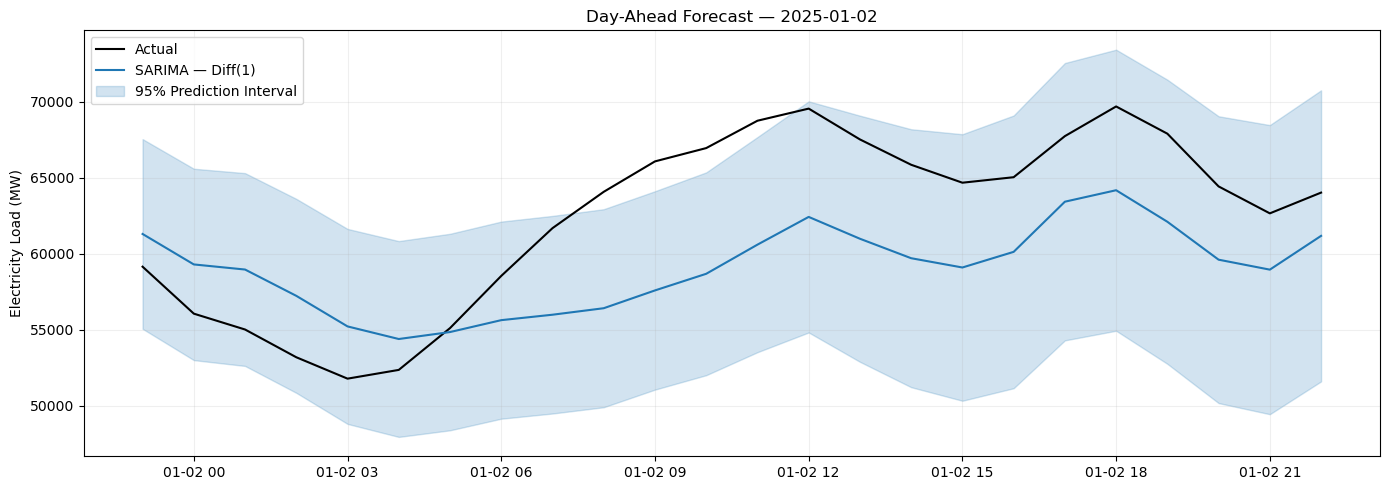

MAPE: 7.69%
95% Interval Coverage: 83.33%


In [37]:
# Visualize day-ahead forecast and 95% prediction interval
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    forecast_day.index,
    forecast_day["actual"],
    label="Actual",
    color="black"
)

ax.plot(
    forecast_day.index,
    forecast_day["prediction"],
    label=f"SARIMA — {family}",
    color="tab:blue"
)

ax.fill_between(
    forecast_day.index,
    forecast_day["lower_95"],
    forecast_day["upper_95"],
    alpha=0.2,
    color="tab:blue",
    label="95% Prediction Interval"
)

ax.set_title(f"Day-Ahead Forecast — {target_day}")
ax.set_ylabel("Electricity Load (MW)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Evaluate valid observations only
valid = forecast_day.dropna()

print(f"MAPE: {evaluate_forecast(valid['actual'], valid['prediction'])['MAPE (%)']:.2f}%")
print(f"95% Interval Coverage: {((valid['actual'] >= valid['lower_95']) & (valid['actual'] <= valid['upper_95'])).mean() * 100:.2f}%")

**Prediction + intervales**

In [38]:
# Walk-forward validation — fixed SARIMA parameters, expanding history
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

sarima_val = {}

for family, fitted_result in best_models.items():

    print(f"\nSTART — {family}", flush=True)

    # Keep estimated parameters fixed
    current_result = fitted_result
    last_seen = current_result.model.data.row_labels[-1]

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        # Skip origins already covered by the fitted training sample
        if origin <= last_seen:
            continue

        # Add only observations available strictly before 11:00 on D
        new_obs = df.loc[
            (df.index > last_seen) & (df.index < origin),
            "load_mw"
        ]

        if not new_obs.empty:
            current_result = current_result.extend(new_obs)
            last_seen = new_obs.index[-1]

        # Forecast from the last available observation to the end of D+1
        horizon = int(
            (targets[-1] - last_seen) / pd.Timedelta(hours=1)
        )

        fc = current_result.get_forecast(steps=horizon)

        pred = fc.predicted_mean.loc[targets]
        ci = fc.conf_int(alpha=0.05).loc[targets]

        # Convert real UTC hours into 24 French clock-hour slots
        local_hours = targets.tz_convert("Europe/Paris").hour
        duplicates = pd.Index(local_hours).duplicated(keep="last")

        point_24 = np.full(24, np.nan)
        lower_24 = np.full(24, np.nan)
        upper_24 = np.full(24, np.nan)

        for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):
            if duplicate:
                continue

            point_24[hour] = pred.iloc[j]
            lower_24[hour] = ci.iloc[j, 0]
            upper_24[hour] = ci.iloc[j, 1]

        daily = pd.DataFrame({
            "prediction": align_24h_forecast(point_24, targets),
            "lower_95": align_24h_forecast(lower_24, targets),
            "upper_95": align_24h_forecast(upper_24, targets)
        })

        daily_forecasts.append(daily)

        if (i + 1) % 30 == 0:
            print(f"{family}: {i + 1}/{len(target_days)} days", flush=True)

    # Store forecasts for this model
    sarima_val[family] = pd.concat(daily_forecasts).sort_index()

    print(f"DONE — {family}", flush=True)


START — Diff(1)
Diff(1): 30/365 days
Diff(1): 60/365 days
Diff(1): 90/365 days
Diff(1): 120/365 days
Diff(1): 150/365 days
Diff(1): 180/365 days
Diff(1): 210/365 days
Diff(1): 240/365 days
Diff(1): 270/365 days
Diff(1): 300/365 days
Diff(1): 330/365 days
Diff(1): 360/365 days
DONE — Diff(1)


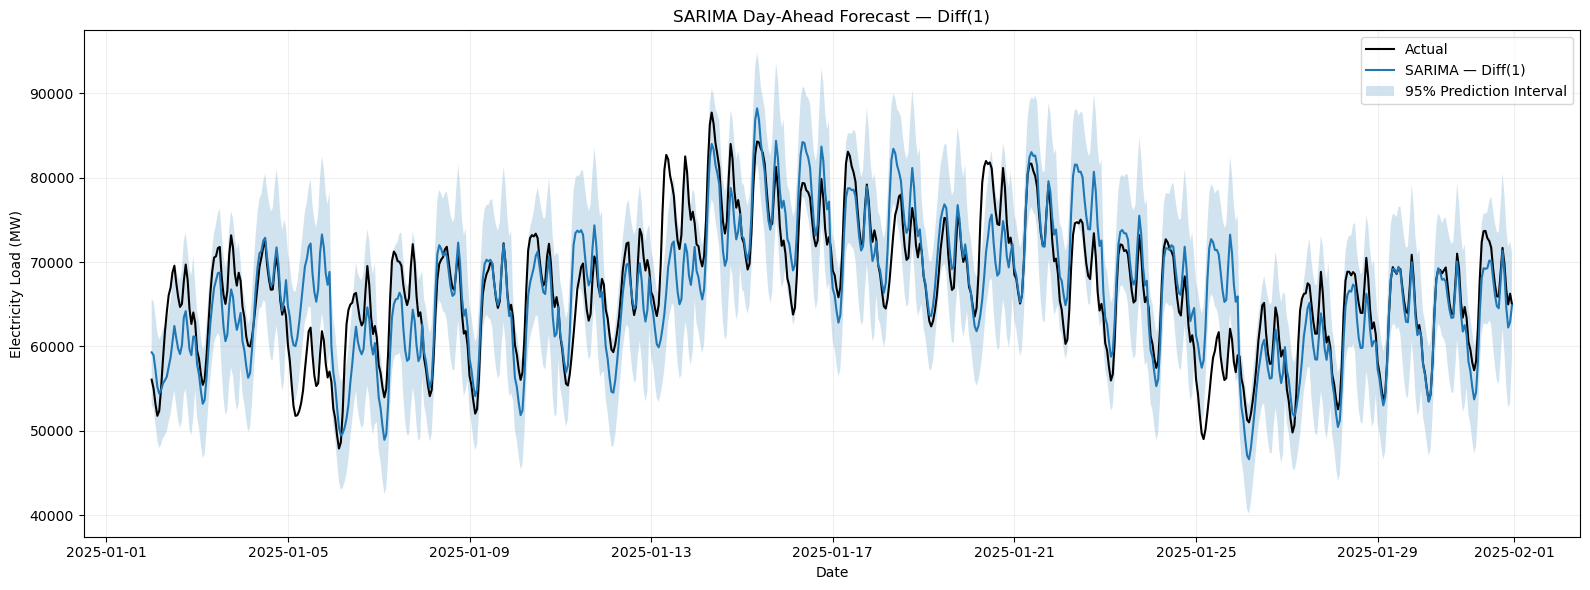

In [39]:
# Plot SARIMA forecasts over one validation month
family = next(iter(sarima_val))

plot_start = "2025-01-02"
plot_end = "2025-01-31"

fc = sarima_val[family].loc[plot_start:plot_end]
actual = df.loc[fc.index, "load_mw"]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(actual.index, actual, label="Actual", color="black", linewidth=1.5)
ax.plot(fc.index, fc["prediction"], label=f"SARIMA — {family}", linewidth=1.5)

ax.fill_between(
    fc.index,
    fc["lower_95"],
    fc["upper_95"],
    alpha=0.2,
    label="95% Prediction Interval"
)

ax.set_title(f"SARIMA Day-Ahead Forecast — {family}")
ax.set_ylabel("Electricity Load (MW)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Choose the best model**

In [40]:
# Exclude unstable models
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

# Common timestamps for all models and benchmarks
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep only timestamps with valid predictions and intervals
for family, forecasts in models_to_evaluate.items():
    valid = forecasts.loc[common_index].notna().all(axis=1)
    valid &= np.isfinite(forecasts.loc[common_index]).all(axis=1)
    common_index = common_index[valid]

assert len(common_index) > 0, "No valid evaluation observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Baselines
for model in ["seasonal_naive_168h", "rte_d1"]:
    comparison[model] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, model]
    )

# SARIMA models
for family, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    metrics["Coverage 95% (%)"] = (
        (y_true >= fc["lower_95"]) &
        (y_true <= fc["upper_95"])
    ).mean() * 100

    metrics["Avg Interval Width (MW)"] = (
        fc["upper_95"] - fc["lower_95"]
    ).mean()

    comparison[family] = metrics

# Final comparison
comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results)

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.813270,1394.695592,1723.854919,NaN,NaN
Diff(1),5.200698,2629.657781,3807.060521,92.959359,15214.546042
seasonal_naive_168h,6.411190,3448.399313,5135.731668,NaN,NaN


## **3.7 — SARIMAX with Temperature-Based Exogenous Variables**

We extend SARIMA by introducing two temperature-based explanatory variables:

- **Heating Degree Days (HDD):** \(HDD_t=\max(0,15-T_t)\)
- **Cooling Degree Days (CDD):** \(CDD_t=\max(0,T_t-22)\)

These features approximate heating and cooling demand.

Since the actual temperature of the forecast day is not available at the 11:00 forecast origin, we use **48-hour lagged temperatures** to construct operationally available HDD and CDD features.

We fit a simple SARIMAX model on the training set and evaluate it using the same day-ahead walk-forward validation protocol as our SARIMA models.

The objective is to assess whether incorporating historical temperature information improves forecasting accuracy.

In [41]:
# Temperature available at least 48 hours before the target
temp_lag48 = df["temperature_c"].shift(48)

# Heating and Cooling Degree features
df["HDD"] = (15 - temp_lag48).clip(lower=0)
df["CDD"] = (temp_lag48 - 22).clip(lower=0)

exog_cols = ["HDD", "CDD"]

display(df[["temperature_c", "HDD", "CDD"]].head(55).tail(10))

,temperature_c,HDD,CDD
datetime_utc,,,
2019-01-02 21:00:00+00:00,3.40,NaN,NaN
2019-01-02 22:00:00+00:00,3.07,NaN,NaN
2019-01-02 23:00:00+00:00,2.47,NaN,NaN
2019-01-03 00:00:00+00:00,2.26,9.15,0.0
2019-01-03 01:00:00+00:00,2.30,8.65,0.0
2019-01-03 02:00:00+00:00,2.13,9.09,0.0
2019-01-03 03:00:00+00:00,2.00,9.30,0.0
2019-01-03 04:00:00+00:00,1.58,9.28,0.0
2019-01-03 05:00:00+00:00,1.62,9.32,0.0


In [42]:
# Training data — 2024
train_sarimax = df.loc["2024-01-01":"2024-12-31"]

y_sarimax = train_sarimax["load_mw"].asfreq("h")
X_sarimax = train_sarimax[exog_cols].asfreq("h")

# Fit SARIMAX
sarimax_model = SARIMAX(
    y_sarimax,
    exog=X_sarimax,
    order=(3, 0, 3),
    seasonal_order=(0, 1, 0, 24),
    trend="n"
)

sarimax_result = sarimax_model.fit(
    disp=False,
    maxiter=100
)

print(f"AIC: {sarimax_result.aic:.2f}")
print(f"Converged: {sarimax_result.mle_retvals['converged']}")

display(sarimax_result.params)

AIC: 136205.36
Converged: True


HDD          -21.373327
CDD           51.441314
ar.L1          2.014861
ar.L2         -1.456864
ar.L3          0.413593
ma.L1         -0.038143
ma.L2         -0.115245
ma.L3          0.047876
sigma2    277067.699954
dtype: float64

In [43]:
# Walk-forward SARIMAX validation
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

current_result = sarimax_result
last_seen = y_sarimax.index[-1]

daily_forecasts = []

for i, day in enumerate(target_days):

    origin, targets = get_forecast_window(day)

    if origin <= last_seen:
        continue

    # Update with observations and exogenous features available before origin
    new_times = df.index[
        (df.index > last_seen) & (df.index < origin)
    ]

    if len(new_times):
        current_result = current_result.extend(
            endog=df.loc[new_times, "load_mw"],
            exog=df.loc[new_times, exog_cols]
        )
        last_seen = new_times[-1]

    # Full forecasting horizon
    future_times = pd.date_range(
        last_seen + pd.Timedelta(hours=1),
        targets[-1],
        freq="h"
    )

    X_future = df.loc[future_times, exog_cols]

    # Verify availability of source temperatures at forecast origin
    assert (future_times - pd.Timedelta(hours=48) < origin).all()
    assert X_future.notna().all().all()

    forecast = current_result.get_forecast(
        steps=len(future_times),
        exog=X_future
    )

    pred = forecast.predicted_mean.loc[targets]
    ci = forecast.conf_int(alpha=0.05).loc[targets]

    # DST alignment
    local_hours = targets.tz_convert("Europe/Paris").hour
    duplicates = pd.Index(local_hours).duplicated(keep="last")

    point_24 = np.full(24, np.nan)
    lower_24 = np.full(24, np.nan)
    upper_24 = np.full(24, np.nan)

    for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):

        if duplicate:
            continue

        point_24[hour] = pred.iloc[j]
        lower_24[hour] = ci.iloc[j, 0]
        upper_24[hour] = ci.iloc[j, 1]

    daily_forecasts.append(pd.DataFrame({
        "prediction": align_24h_forecast(point_24, targets),
        "lower_95": align_24h_forecast(lower_24, targets),
        "upper_95": align_24h_forecast(upper_24, targets)
    }))

    if (i + 1) % 30 == 0:
        print(f"SARIMAX: {i + 1}/{len(target_days)} days", flush=True)

sarimax_val = pd.concat(daily_forecasts).sort_index()

print("SARIMAX validation completed")

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

SARIMAX: 30/365 days


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

SARIMAX: 60/365 days


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

...

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

SARIMAX: 330/365 days


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

SARIMAX: 360/365 days
SARIMAX validation completed


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  

**compare**

In [44]:
# Include retained SARIMA models and SARIMAX
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

models_to_evaluate["SARIMAX (HDD + CDD)"] = sarimax_val

# Common evaluation timestamps
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep identical valid observations across all models
for forecasts in models_to_evaluate.values():
    values = forecasts.loc[common_index]
    valid = pd.Series(
        np.isfinite(values.to_numpy()).all(axis=1),
        index=common_index
    )
    common_index = common_index[valid]

assert len(common_index) > 0, "No common valid observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Benchmarks
for model in ["seasonal_naive_168h", "rte_d1"]:
    comparison[model] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, model]
    )

# Statistical models
for family, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    metrics["Coverage 95% (%)"] = (
        (y_true >= fc["lower_95"]) &
        (y_true <= fc["upper_95"])
    ).mean() * 100

    metrics["Avg Interval Width (MW)"] = (
        fc["upper_95"] - fc["lower_95"]
    ).mean()

    comparison[family] = metrics

comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results.round(2))

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.81,1394.70,1723.85,NaN,NaN
Diff(1),5.20,2629.66,3807.06,92.96,15214.55
SARIMAX (HDD + CDD),5.22,2636.01,3810.78,92.95,15272.21
seasonal_naive_168h,6.41,3448.40,5135.73,NaN,NaN


### **3.8 — Holt-Winters Exponential Smoothing**

We evaluate Holt-Winters as an alternative statistical forecasting approach.

Unlike SARIMA, Holt-Winters explicitly models three components through exponential smoothing:

- **Level:** the underlying consumption level.
- **Trend:** the local evolution of electricity demand.
- **Seasonality:** the recurring daily consumption pattern.

Based on our exploratory analysis, we select an additive seasonal model with a 24-hour period and a damped additive trend.

Model smoothing parameters are estimated on the training set. During walk-forward validation, the historical level, trend and seasonal states are updated using only observations available before the 11:00 forecast origin.

We evaluate day-ahead predictions on 2025 using MAPE, MAE and RMSE, and compare Holt-Winters against SARIMA, SARIMAX and the existing benchmarks.

In [45]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import pandas as pd
import numpy as np
import time
import warnings

# Training data — 2024
y_hw = train.loc["2024-01-01":"2024-12-31", "load_mw"].asfreq("h")

hw_configs = [
    {"trend": None,  "damped_trend": False, "seasonal": "add", "seasonal_periods": 24},
    {"trend": "add", "damped_trend": True, "seasonal": "mul", "seasonal_periods": 168},
    {"trend": "add", "damped_trend": True,  "seasonal": "add", "seasonal_periods": 24},
    {"trend": "add", "damped_trend": True,  "seasonal": "mul", "seasonal_periods": 24},
]

hw_models = {}
hw_results = []

for i, config in enumerate(hw_configs, start=1):

    name = f"HW_{i}"
    start = time.perf_counter()

    print(f"[{i}/{len(hw_configs)}] Training {name}", flush=True)

    try:
        model = ExponentialSmoothing(
            y_hw,
            **config,
            initialization_method="estimated"
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = model.fit(optimized=True)

        hw_models[name] = result

        hw_results.append({
            "Model": name,
            **config,
            "AIC": result.aic,
            "SSE": result.sse,
            "Alpha": result.params["smoothing_level"],
            "Beta": result.params["smoothing_trend"],
            "Gamma": result.params["smoothing_seasonal"],
            "Phi": result.params["damping_trend"],
            "Time (s)": time.perf_counter() - start
        })

        print(f"DONE — {name} | AIC={result.aic:.2f}", flush=True)

    except Exception as e:
        print(f"FAILED — {name}: {e}", flush=True)

hw_results_df = pd.DataFrame(hw_results).sort_values("AIC")

display(hw_results_df.round(4))

[1/4] Training HW_1
DONE — HW_1 | AIC=118719.76
[2/4] Training HW_2
DONE — HW_2 | AIC=121230.55
[3/4] Training HW_3
DONE — HW_3 | AIC=118725.56
[4/4] Training HW_4
DONE — HW_4 | AIC=118983.85


,Model,trend,damped_trend,seasonal,seasonal_periods,AIC,SSE,Alpha,Beta,Gamma,Phi,Time (s)
0,HW_1,None,False,add,24,118719.7580,6.477800e+09,0.8239,NaN,0.1761,NaN,0.1118
2,HW_3,add,True,add,24,118725.5558,6.477651e+09,0.8225,0.0,0.1775,0.9882,0.8766
3,HW_4,add,True,mul,24,118983.8466,6.670974e+09,0.8234,0.0,0.1766,0.9949,0.8968
1,HW_2,add,True,mul,168,121230.5542,8.337615e+09,0.4911,0.0,0.5089,0.9930,2.3269


In [46]:
# Walk-forward validation — all Holt-Winters configurations
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

hw_val_models = {}

for name, trained in hw_models.items():

    print(f"\nSTART — {name}", flush=True)

    config = hw_configs[int(name.split("_")[1]) - 1]
    params = trained.params

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        # Skip origins overlapping training data
        if origin <= y_hw.index[-1]:
            continue

        # Historical observations available strictly before origin
        last_available = origin - pd.Timedelta(hours=1)

        history = df.loc[
            y_hw.index[0]:last_available, "load_mw"
        ].asfreq("h")

        # Update states using fixed smoothing parameters
        model = ExponentialSmoothing(
            history,
            **config,
            initialization_method="known",
            initial_level=params["initial_level"],
            initial_trend=(
                params["initial_trend"]
                if config["trend"] is not None else None
            ),
            initial_seasonal=params["initial_seasons"]
        )

        fitted = model.fit(
            smoothing_level=params["smoothing_level"],
            smoothing_trend=params["smoothing_trend"],
            smoothing_seasonal=params["smoothing_seasonal"],
            damping_trend=params["damping_trend"],
            optimized=False
        )

        # Forecast through the end of D+1
        horizon = int(
            (targets[-1] - last_available) / pd.Timedelta(hours=1)
        )

        pred = fitted.forecast(horizon).loc[targets]

        # DST alignment
        local_hours = targets.tz_convert("Europe/Paris").hour
        duplicates = pd.Index(local_hours).duplicated(keep="last")

        point_24 = np.full(24, np.nan)

        for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):
            if not duplicate:
                point_24[hour] = pred.iloc[j]

        daily_forecasts.append(
            align_24h_forecast(point_24, targets)
        )

        if (i + 1) % 30 == 0:
            print(f"{name}: {i + 1}/{len(target_days)} days", flush=True)

    hw_val_models[name] = (
        pd.concat(daily_forecasts)
        .sort_index()
        .to_frame("prediction")
    )

    print(f"DONE — {name}", flush=True)


START — HW_1
HW_1: 30/365 days
HW_1: 60/365 days
HW_1: 90/365 days
HW_1: 120/365 days
HW_1: 150/365 days
HW_1: 180/365 days
HW_1: 210/365 days
HW_1: 240/365 days
HW_1: 270/365 days
HW_1: 300/365 days
HW_1: 330/365 days
HW_1: 360/365 days
DONE — HW_1

START — HW_2
HW_2: 30/365 days
HW_2: 60/365 days
HW_2: 90/365 days
HW_2: 120/365 days
HW_2: 150/365 days
HW_2: 180/365 days
HW_2: 210/365 days
HW_2: 240/365 days
HW_2: 270/365 days
HW_2: 300/365 days
HW_2: 330/365 days
HW_2: 360/365 days
DONE — HW_2

START — HW_3
HW_3: 30/365 days
HW_3: 60/365 days
HW_3: 90/365 days
HW_3: 120/365 days
HW_3: 150/365 days
HW_3: 180/365 days
HW_3: 210/365 days
HW_3: 240/365 days
HW_3: 270/365 days
HW_3: 300/365 days
HW_3: 330/365 days
HW_3: 360/365 days
DONE — HW_3

START — HW_4
HW_4: 30/365 days
HW_4: 60/365 days
HW_4: 90/365 days
HW_4: 120/365 days
HW_4: 150/365 days
HW_4: 180/365 days
HW_4: 210/365 days
HW_4: 240/365 days
HW_4: 270/365 days
HW_4: 300/365 days
HW_4: 330/365 days
HW_4: 360/365 days
DONE — H

In [47]:
# Collect all statistical models
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

models_to_evaluate["SARIMAX (HDD + CDD)"] = sarimax_val

for name, forecasts in hw_val_models.items():
    models_to_evaluate[name] = forecasts

# Common evaluation timestamps
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep only timestamps with finite point forecasts
for forecasts in models_to_evaluate.values():
    prediction = forecasts.loc[common_index, "prediction"]
    common_index = common_index[np.isfinite(prediction.to_numpy())]

assert len(common_index) > 0, "No common valid observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Benchmarks
for name in ["seasonal_naive_168h", "rte_d1"]:
    comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )

# Statistical models
for name, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    # Prediction intervals, if available
    if {"lower_95", "upper_95"}.issubset(fc.columns):

        valid_intervals = (
            np.isfinite(fc["lower_95"]) &
            np.isfinite(fc["upper_95"])
        )

        if valid_intervals.all():

            metrics["Coverage 95% (%)"] = (
                (y_true >= fc["lower_95"]) &
                (y_true <= fc["upper_95"])
            ).mean() * 100

            metrics["Avg Interval Width (MW)"] = (
                fc["upper_95"] - fc["lower_95"]
            ).mean()

    comparison[name] = metrics

comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results.round(2))

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.81,1394.70,1723.85,NaN,NaN
Diff(1),5.20,2629.66,3807.06,92.96,15214.55
SARIMAX (HDD + CDD),5.22,2636.01,3810.78,92.95,15272.21
HW_2,5.92,3009.07,3887.95,NaN,NaN
seasonal_naive_168h,6.41,3448.40,5135.73,NaN,NaN
HW_4,7.38,3687.58,4849.70,NaN,NaN
HW_3,7.61,3757.53,4953.84,NaN,NaN
HW_1,7.62,3762.13,4958.61,NaN,NaN


## **4. Machine Learning — LightGBM**

We now investigate gradient boosting approaches for day-ahead electricity demand forecasting using LightGBM.

Unlike the statistical models explored previously, LightGBM learns nonlinear relationships between electricity consumption, calendar effects, historical demand and temperature-based features.

We adopt a **global direct multi-horizon forecasting strategy**: one model predicts each target hour independently using its associated features, without recursively feeding previous predictions into subsequent horizons.

All models follow the same operational forecasting protocol: predictions are issued at **11:00 Europe/Paris on day D** for the 24 local clock-hour slots of D+1.

### Section Overview

**4.1 — Feature Engineering**

Transform the hourly time series into a supervised tabular dataset, including historical consumption, lagged temperature, calendar indicators and RTE forecast information.

Two calendar representations will be constructed: detailed binary flags and aggregated positive/negative activity flags.

**4.2 — Direct LightGBM**

Train models to predict electricity consumption directly, comparing detailed and aggregated calendar features.

**4.3 — Trend + LightGBM**

Estimate a local trend using historical observations and train LightGBM to predict the remaining consumption component. Compare both calendar representations.

**4.4 — RTE Error Correction with LightGBM**

Train LightGBM to predict and correct RTE day-ahead forecast errors, first using historical RTE errors and then incorporating the most promising calendar and weather features.

We assume that the RTE D+1 forecasts are available at the 11:00 forecast origin. This assumption will be explicitly acknowledged as a methodological limitation.

**4.5 — Hyperparameter Tuning & Walk-forward Validation**

Optimize promising configurations and evaluate all candidates on the 2025 validation set using the same timestamps, forecast origins and DST conventions.

MAPE is the primary model-selection metric, complemented by MAE and RMSE.

**4.6 — Comparison with Statistical Models and Benchmarks**

Compare the LightGBM variants against the previously evaluated SARIMA, SARIMAX, Holt-Winters, Seasonal Naive and RTE D+1 models stored in `comparison_results`.

The strongest configurations will be retained for final evaluation on the untouched 2026 test set.